# PRCP-1004 · FIFA 20 Players — End-to-End Data Science Project

**Domain:** Sports analytics  |  **Data:** `players_20.csv` (FIFA 20 Career Mode, 18,278 players × 104 columns)

| Part | Content |
|---|---|
| **Task 1** | Complete data analysis report (overview, cleaning, EDA, insights) |
| **Task 2** | Clustering football players on their skill sets |
| **Task 3** | Q1 Top-10 countries · Q2 Overall vs. age · Q3 Best-paid offensive position |
| **Report A** | Model comparison & production recommendation |
| **Report B** | Challenges faced and techniques used |

> **Note on the data.** The brief mentions FIFA 15–20, but the supplied file contains only the **FIFA 20** edition, so
> the multi-version "ideas" (e.g. Messi vs. Ronaldo over time) cannot be done longitudinally. Where useful I do the
> single-version equivalent.

In [1]:
import os, time, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 90
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
RANDOM_STATE = 42

DATA_PATH = next(p for p in ['players_20.csv', '/mnt/user-data/uploads/players_20.csv'] if os.path.exists(p))
print('Using', DATA_PATH)

Using players_20.csv


---
# TASK 1 — Complete Data Analysis Report
## 1.1 Data overview

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f'Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}')
raw.head()

Rows: 18,278 | Columns: 104


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club,overall,potential,value_eur,wage_eur,player_positions,preferred_foot,international_reputation,weak_foot,skill_moves,work_rate,body_type,real_face,release_clause_eur,player_tags,team_position,team_jersey_number,loaned_from,joined,contract_valid_until,nation_position,...,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,ram,lm,lcm,cm,rcm,rm,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,32,1987-06-24,170,72,Argentina,FC Barcelona,94,94,95500000,565000,"RW, CF, ST",Left,5,4,4,Medium/Low,Messi,Yes,"195,800,000.00","#Dribbler, #Distance Shooter, #Crosser, #FK Sp...",RW,10.00,NaN,2004-07-01,"2,021.00",NaN,...,11,15,14,8,89+2,89+2,89+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,93+2,92+2,87+2,87+2,87+2,92+2,68+2,66+2,66+2,66+2,68+2,63+2,52+2,52+2,52+2,63+2
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,34,1985-02-05,187,83,Portugal,Juventus,93,93,58500000,405000,"ST, LW",Right,5,4,5,High/Low,C. Ronaldo,Yes,"96,500,000.00","#Speedster, #Dribbler, #Distance Shooter, #Acr...",LW,7.00,NaN,2018-07-10,"2,022.00",LS,...,11,15,14,11,91+3,91+3,91+3,89+3,90+3,90+3,90+3,89+3,88+3,88+3,88+3,88+3,81+3,81+3,81+3,88+3,65+3,61+3,61+3,61+3,65+3,61+3,53+3,53+3,53+3,61+3
2,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Junior,27,1992-02-05,175,68,Brazil,Paris Saint-Germain,92,92,105500000,290000,"LW, CAM",Right,5,5,5,High/Medium,Neymar,Yes,"195,200,000.00","#Speedster, #Dribbler, #Playmaker , #Crosser,...",CAM,10.00,NaN,2017-08-03,"2,022.00",LW,...,9,15,15,11,84+3,84+3,84+3,90+3,89+3,89+3,89+3,90+3,90+3,90+3,90+3,89+3,82+3,82+3,82+3,89+3,66+3,61+3,61+3,61+3,66+3,61+3,46+3,46+3,46+3,61+3
3,200389,https://sofifa.com/player/200389/jan-oblak/20/...,J. Oblak,Jan Oblak,26,1993-01-07,188,87,Slovenia,Atlético Madrid,91,93,77500000,125000,GK,Right,3,3,1,Medium/Medium,Normal,Yes,"164,700,000.00",NaN,GK,13.00,NaN,2014-07-16,"2,023.00",GK,...,92,78,90,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,183277,https://sofifa.com/player/183277/eden-hazard/2...,E. Hazard,Eden Hazard,28,1991-01-07,175,74,Belgium,Real Madrid,91,91,90000000,470000,"LW, CF",Right,4,4,4,High/Medium,Normal,Yes,"184,500,000.00","#Speedster, #Dribbler, #Acrobat",LW,7.00,NaN,2019-07-01,"2,024.00",LF,...,12,6,8,8,83+3,83+3,83+3,89+3,88+3,88+3,88+3,89+3,89+3,89+3,89+3,89+3,83+3,83+3,83+3,89+3,66+3,63+3,63+3,63+3,66+3,61+3,49+3,49+3,49+3,61+3


In [3]:
print(raw.dtypes.value_counts(), '\n')
print('Duplicate rows            :', raw.duplicated().sum())
print('Duplicate sofifa_id values:', raw.sofifa_id.duplicated().sum())
raw.select_dtypes('number').describe().T

int64      45
object     43
float64    16
Name: count, dtype: int64 

Duplicate rows            : 0
Duplicate sofifa_id values: 0


,count,mean,std,min,25%,50%,75%,max
sofifa_id,"18,278.00","219,738.86","27,960.20",768.00,"204,445.50","226,165.00","240,795.75","252,905.00"
age,"18,278.00",25.28,4.66,16.00,22.00,25.00,29.00,42.00
height_cm,"18,278.00",181.36,6.76,156.00,177.00,181.00,186.00,205.00
weight_kg,"18,278.00",75.28,7.05,50.00,70.00,75.00,80.00,110.00
overall,"18,278.00",66.24,6.95,48.00,62.00,66.00,71.00,94.00
...,...,...,...,...,...,...,...,...
goalkeeping_diving,"18,278.00",16.57,17.74,1.00,8.00,11.00,14.00,90.00
goalkeeping_handling,"18,278.00",16.35,17.00,1.00,8.00,11.00,14.00,92.00
goalkeeping_kicking,"18,278.00",16.21,16.61,1.00,8.00,11.00,14.00,93.00
goalkeeping_positioning,"18,278.00",16.37,17.14,1.00,8.00,11.00,14.00,91.00


## 1.2 Missing values

,loaned_from,nation_jersey_number,nation_position,player_tags,gk_positioning,gk_diving,gk_reflexes,gk_speed,gk_handling,gk_kicking,player_traits,cm,rcm,lcm,lm,ram,rs,rm,lam,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,cam,rb,rw,physic,pace,shooting,passing,rf,defending,dribbling,ls,st,lw,lf,cf,release_clause_eur,joined,contract_valid_until,team_jersey_number,team_position
missing,"17,230.00","17,152.00","17,152.00","16,779.00","16,242.00","16,242.00","16,242.00","16,242.00","16,242.00","16,242.00","10,712.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","2,036.00","1,298.00","1,288.00",240.00,240.00,240.00
pct,94.27,93.84,93.84,91.80,88.86,88.86,88.86,88.86,88.86,88.86,58.61,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,11.14,7.10,7.05,1.31,1.31,1.31


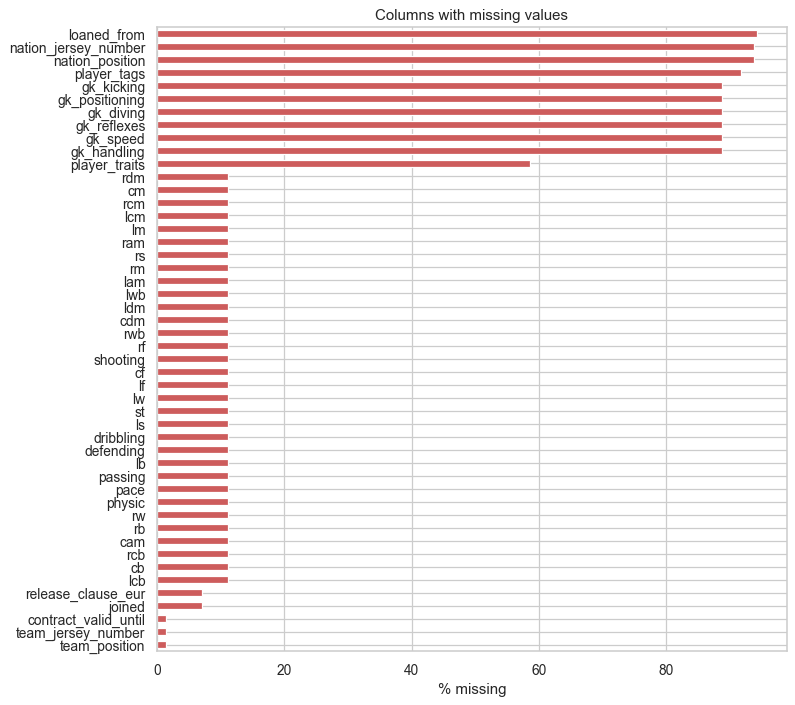

In [4]:
miss = raw.isna().sum().to_frame('missing')
miss['pct'] = miss.missing / len(raw) * 100
miss = miss[miss.missing > 0].sort_values('pct', ascending=False)
display(miss.T)

fig, ax = plt.subplots(figsize=(9, 8))
miss.pct.sort_values().plot.barh(ax=ax, color='indianred')
ax.set_xlabel('% missing'); ax.set_title('Columns with missing values')
plt.tight_layout()

**Why are values missing?** Most gaps are *structural*, not random:
* `gk_*`, `player_traits`, `player_tags`, `loaned_from`, `nation_position` etc. only apply to some players.
* `pace, shooting, passing, dribbling, defending, physic` and every positional rating (`st`, `lw` …) are **only filled for outfield players** — goalkeepers have none (2,036 rows).
* `team_position`, `contract_valid_until` are empty for players without a current club contract.

Let me verify that claim before acting on it.

In [5]:
gk_mask = raw.player_positions.str.startswith('GK')
print('Goalkeepers                      :', gk_mask.sum())
print('Missing pace among goalkeepers   :', raw.loc[gk_mask, 'pace'].isna().sum())
print('Missing pace among outfielders   :', raw.loc[~gk_mask, 'pace'].isna().sum())
print('Missing goalkeeping_diving (all) :', raw.goalkeeping_diving.isna().sum())
print('Zero wage rows                   :', (raw.wage_eur == 0).sum(), '| Zero value rows:', (raw.value_eur == 0).sum())
print('Missing team_position & contract :', raw.team_position.isna().sum(), raw.contract_valid_until.isna().sum())

Goalkeepers                      : 2036
Missing pace among goalkeepers   : 2036
Missing pace among outfielders   : 0
Missing goalkeeping_diving (all) : 0
Zero wage rows                   : 240 | Zero value rows: 250
Missing team_position & contract : 240 240


## 1.3 Pre-processing
Steps (reasons are expanded in **Report B**):
1. Drop identifiers / URLs / >80 %-missing / duplicated-meaning columns.
2. Rename attributes to the naming used in the brief.
3. Convert positional strings such as `'89+2'` into numbers (89 + 2 = 91).
4. Split `work_rate` into `atk_work_rate`, `def_work_rate` (Low 0 · Medium 0.5 · High 1) and label-encode `preferred_foot` (Left 0 · Right 1).
5. Derive `primary_position` (first listed) and a 4-way `position_group` (GK / DEF / MID / FWD).
6. Keep `value_eur`/`wage_eur` and add `value_m`; zero-wage rows are handled in the analysis that needs wages.

In [6]:
df = raw.copy()

# 1. drop columns that are identifiers, nearly empty, or derived composites
drop_cols = ['player_url', 'dob', 'real_face', 'player_tags', 'loaned_from', 'nation_position', 'nation_jersey_number',
             'team_jersey_number', 'player_traits', 'gk_diving', 'gk_handling', 'gk_kicking', 'gk_reflexes',
             'gk_speed', 'gk_positioning',                       # sparse FIFA "GK composites"
             'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic']   # composites, NaN for all GKs
df = df.drop(columns=drop_cols)

# 2. rename to brief-style attribute names
rename = {'attacking_crossing': 'crossing', 'attacking_finishing': 'finishing', 'attacking_heading_accuracy': 'heading_accuracy',
          'attacking_short_passing': 'short_passing', 'attacking_volleys': 'volleys', 'skill_dribbling': 'dribbling',
          'skill_curve': 'curve', 'skill_fk_accuracy': 'fk_accuracy', 'skill_long_passing': 'long_passing',
          'skill_ball_control': 'ball_control', 'movement_acceleration': 'acceleration', 'movement_sprint_speed': 'sprint_speed',
          'movement_agility': 'agility', 'movement_reactions': 'reactions', 'movement_balance': 'balance',
          'power_shot_power': 'shot_power', 'power_jumping': 'jumping', 'power_stamina': 'stamina', 'power_strength': 'strength',
          'power_long_shots': 'long_shots', 'mentality_aggression': 'aggression', 'mentality_interceptions': 'interceptions',
          'mentality_positioning': 'positioning', 'mentality_vision': 'vision', 'mentality_penalties': 'penalties',
          'mentality_composure': 'composure', 'defending_marking': 'marking', 'defending_standing_tackle': 'standing_tackle',
          'defending_sliding_tackle': 'sliding_tackle', 'goalkeeping_diving': 'gk_diving', 'goalkeeping_handling': 'gk_handling',
          'goalkeeping_kicking': 'gk_kicking', 'goalkeeping_positioning': 'gk_positioning', 'goalkeeping_reflexes': 'gk_reflexes'}
df = df.rename(columns=rename)

# 3. positional ratings like '89+2' -> 91  (GKs are NaN by design)
pos_cols = ['ls', 'st', 'rs', 'lw', 'lf', 'cf', 'rf', 'rw', 'lam', 'cam', 'ram', 'lm', 'lcm', 'cm', 'rcm', 'rm',
            'lwb', 'ldm', 'cdm', 'rdm', 'rwb', 'lb', 'lcb', 'cb', 'rcb', 'rb']
def parse_rating(x):
    if pd.isna(x): return np.nan
    return float(sum(int(p) for p in str(x).split('+')))
for c in pos_cols:
    df[c] = df[c].map(parse_rating)

# 4. encodings
wr = {'Low': 0, 'Medium': 0.5, 'High': 1}
df['atk_work_rate'] = df.work_rate.str.split('/').str[0].str.strip().map(wr)
df['def_work_rate'] = df.work_rate.str.split('/').str[1].str.strip().map(wr)
df['preferred_foot_enc'] = df.preferred_foot.map({'Left': 0, 'Right': 1})

# 5. positions
df['primary_position'] = df.player_positions.str.split(',').str[0].str.strip()
group_map = {'GK': 'GK', 'CB': 'DEF', 'LB': 'DEF', 'RB': 'DEF', 'LWB': 'DEF', 'RWB': 'DEF',
             'CDM': 'MID', 'CM': 'MID', 'CAM': 'MID', 'LM': 'MID', 'RM': 'MID',
             'ST': 'FWD', 'CF': 'FWD', 'LW': 'FWD', 'RW': 'FWD'}
df['position_group'] = df.primary_position.map(group_map)

# 6. money in millions
df['value_m'] = df.value_eur / 1e6
df['wage_k'] = df.wage_eur / 1e3

SKILLS = ['crossing', 'finishing', 'heading_accuracy', 'short_passing', 'volleys', 'dribbling', 'curve', 'fk_accuracy',
          'long_passing', 'ball_control', 'acceleration', 'sprint_speed', 'agility', 'reactions', 'balance', 'shot_power',
          'jumping', 'stamina', 'strength', 'long_shots', 'aggression', 'interceptions', 'positioning', 'vision',
          'penalties', 'composure', 'marking', 'standing_tackle', 'sliding_tackle']
GK_SKILLS = ['gk_diving', 'gk_handling', 'gk_kicking', 'gk_positioning', 'gk_reflexes']

print('Shape after cleaning:', df.shape)
print('Unmapped positions  :', df.position_group.isna().sum())
print('Missing in skill columns:', df[SKILLS + GK_SKILLS].isna().sum().sum())
print('Missing in work-rate / foot encodings:', df[['atk_work_rate', 'def_work_rate', 'preferred_foot_enc']].isna().sum().sum())
df[['short_name', 'age', 'height_cm', 'overall', 'potential', 'value_m', 'wage_k', 'primary_position', 'position_group',
    'preferred_foot_enc', 'atk_work_rate', 'def_work_rate', 'st', 'rw']].head()

Shape after cleaning: (18278, 90)
Unmapped positions  : 0
Missing in skill columns: 0
Missing in work-rate / foot encodings: 0


,short_name,age,height_cm,overall,potential,value_m,wage_k,primary_position,position_group,preferred_foot_enc,atk_work_rate,def_work_rate,st,rw
0,L. Messi,32,170,94,94,95.50,565.00,RW,FWD,0,0.50,0.00,91.00,95.00
1,Cristiano Ronaldo,34,187,93,93,58.50,405.00,ST,FWD,1,1.00,0.00,94.00,92.00
2,Neymar Jr,27,175,92,92,105.50,290.00,LW,FWD,1,1.00,0.50,87.00,93.00
3,J. Oblak,26,188,91,93,77.50,125.00,GK,GK,1,0.50,0.50,NaN,NaN
4,E. Hazard,28,175,91,91,90.00,470.00,LW,FWD,1,1.00,0.50,86.00,92.00


## 1.4 Univariate analysis — numeric variables

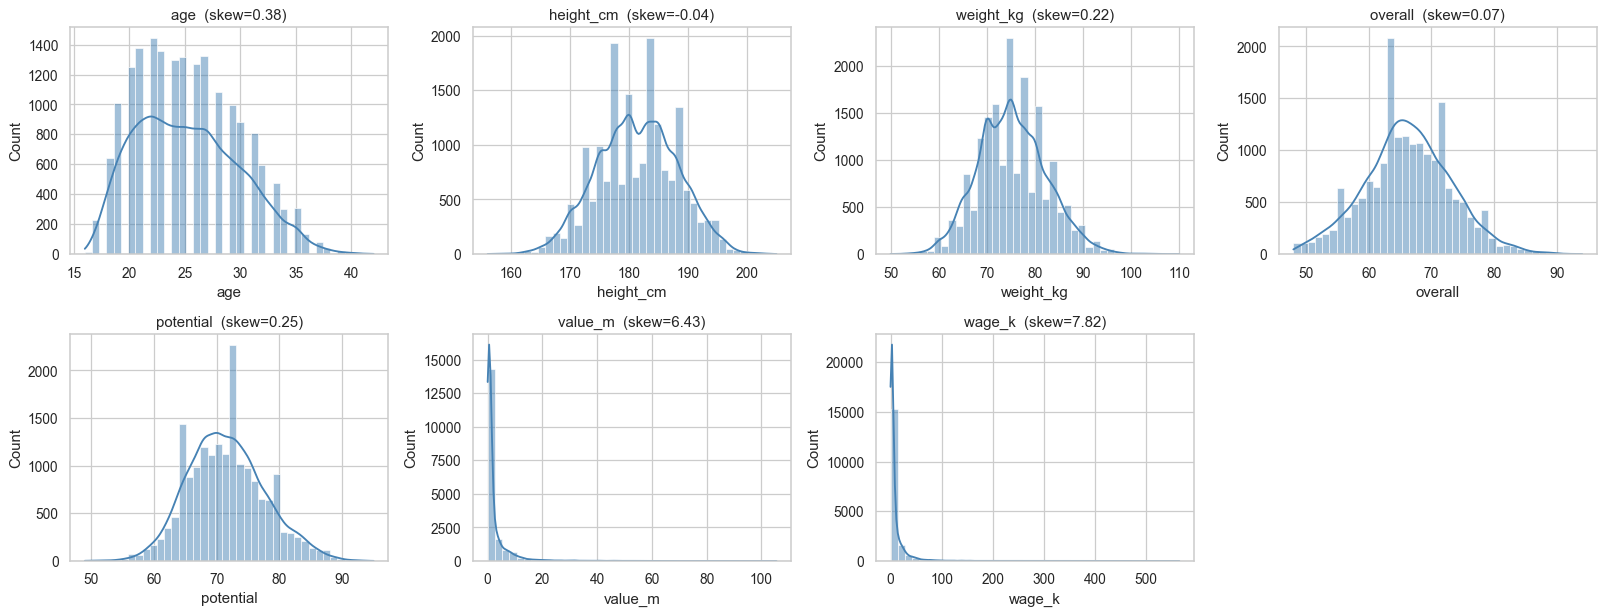

In [7]:
num_vars = ['age', 'height_cm', 'weight_kg', 'overall', 'potential', 'value_m', 'wage_k']
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, c in zip(axes, num_vars):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(f'{c}  (skew={df[c].skew():.2f})')
axes[-1].axis('off')
plt.tight_layout()

In [8]:
summary = df[num_vars].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).T
summary

,mean,median,std,min,max,skew
age,25.28,25.00,4.66,16.00,42.00,0.38
height_cm,181.36,181.00,6.76,156.00,205.00,-0.04
weight_kg,75.28,75.00,7.05,50.00,110.00,0.22
overall,66.24,66.00,6.95,48.00,94.00,0.07
potential,71.55,71.00,6.14,49.00,95.00,0.25
value_m,2.48,0.70,5.59,0.00,105.50,6.43
wage_k,9.46,3.00,21.35,0.00,565.00,7.82


**Reading the distributions**
* `overall`, `age`, `height_cm`, `weight_kg` are roughly bell-shaped (skew ≈ 0–0.5).
* `value_m` and `wage_k` are **extremely right-skewed** (a handful of superstars are worth > €80 M while the median player is worth ≈ €0.7 M) → analyses on money use **log scale / medians / non-parametric tests**.

## 1.5 Univariate analysis — categorical variables

preferred_foot
Right   76.40
Left    23.60


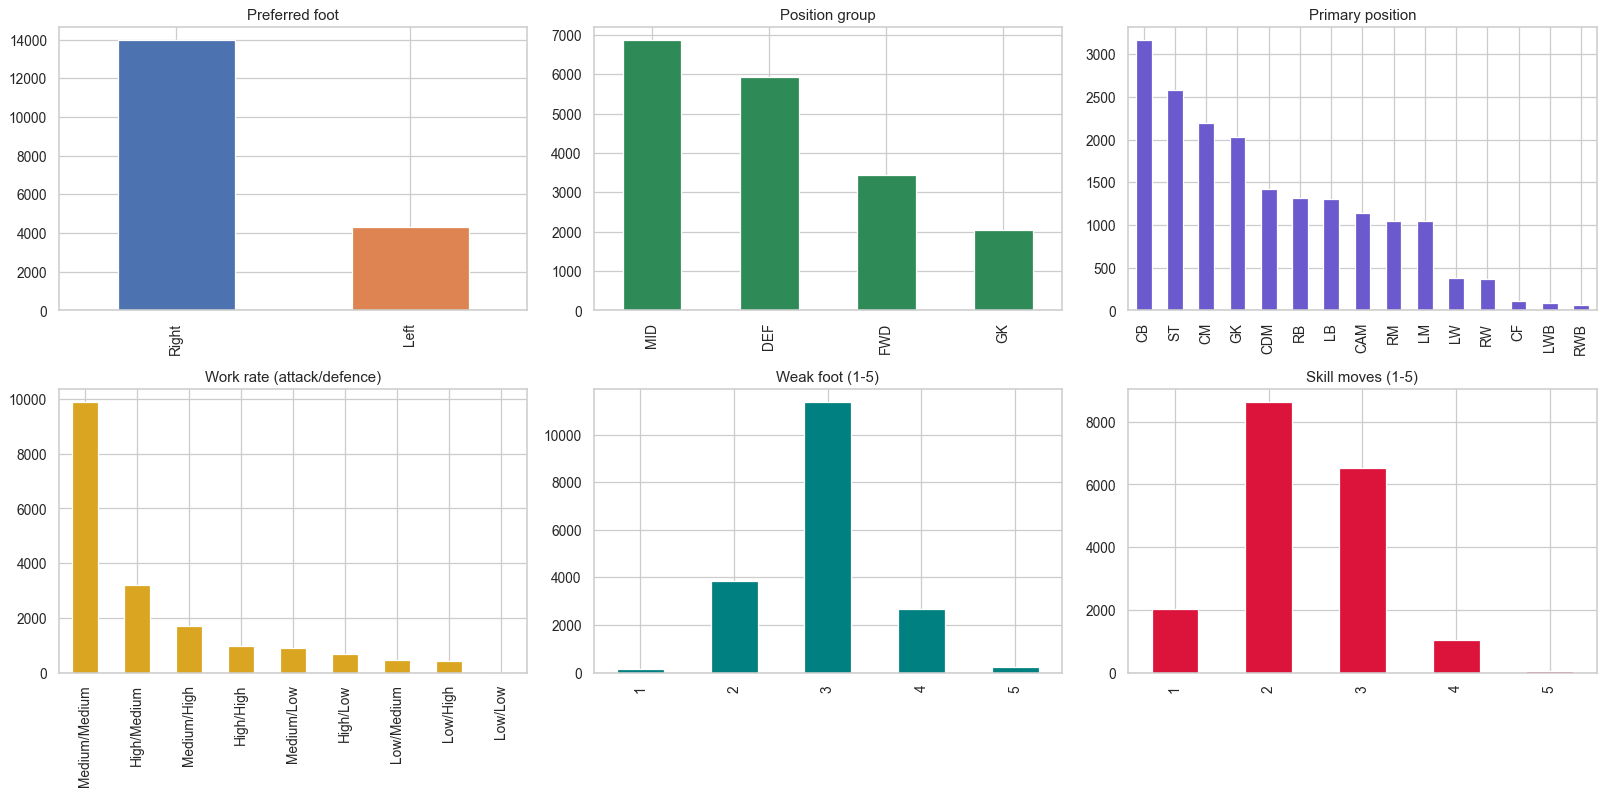

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9)); axes = axes.ravel()
df.preferred_foot.value_counts().plot.bar(ax=axes[0], color=['#4c72b0', '#dd8452']); axes[0].set_title('Preferred foot')
df.position_group.value_counts().plot.bar(ax=axes[1], color='seagreen'); axes[1].set_title('Position group')
df.primary_position.value_counts().plot.bar(ax=axes[2], color='slateblue'); axes[2].set_title('Primary position')
df.work_rate.value_counts().plot.bar(ax=axes[3], color='goldenrod'); axes[3].set_title('Work rate (attack/defence)')
df.weak_foot.value_counts().sort_index().plot.bar(ax=axes[4], color='teal'); axes[4].set_title('Weak foot (1-5)')
df.skill_moves.value_counts().sort_index().plot.bar(ax=axes[5], color='crimson'); axes[5].set_title('Skill moves (1-5)')
for a in axes: a.set_xlabel('')
plt.tight_layout()
print((df.preferred_foot.value_counts(normalize=True) * 100).round(1).to_string())

## 1.6 Outliers (IQR rule)

In [10]:
rows = []
for c in ['age', 'height_cm', 'weight_kg', 'overall', 'potential', 'value_m', 'wage_k']:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum()
    rows.append((c, n, n / len(df) * 100))
pd.DataFrame(rows, columns=['variable', 'n_outliers', 'pct']).set_index('variable')

,n_outliers,pct
variable,,
age,19,0.10
height_cm,89,0.49
weight_kg,73,0.40
overall,151,0.83
potential,145,0.79
value_m,2511,13.74
wage_k,2360,12.91


Outliers in `value_m`/`wage_k`/`overall` are **genuine stars** (Messi, Neymar, Mbappé …) rather than data errors, so they are **kept**; instead the heavy tails are handled with log transforms, medians and robust tests. The few `height`/`weight` outliers are plausible goalkeepers/centre-backs.

## 1.7 Bivariate & multivariate analysis

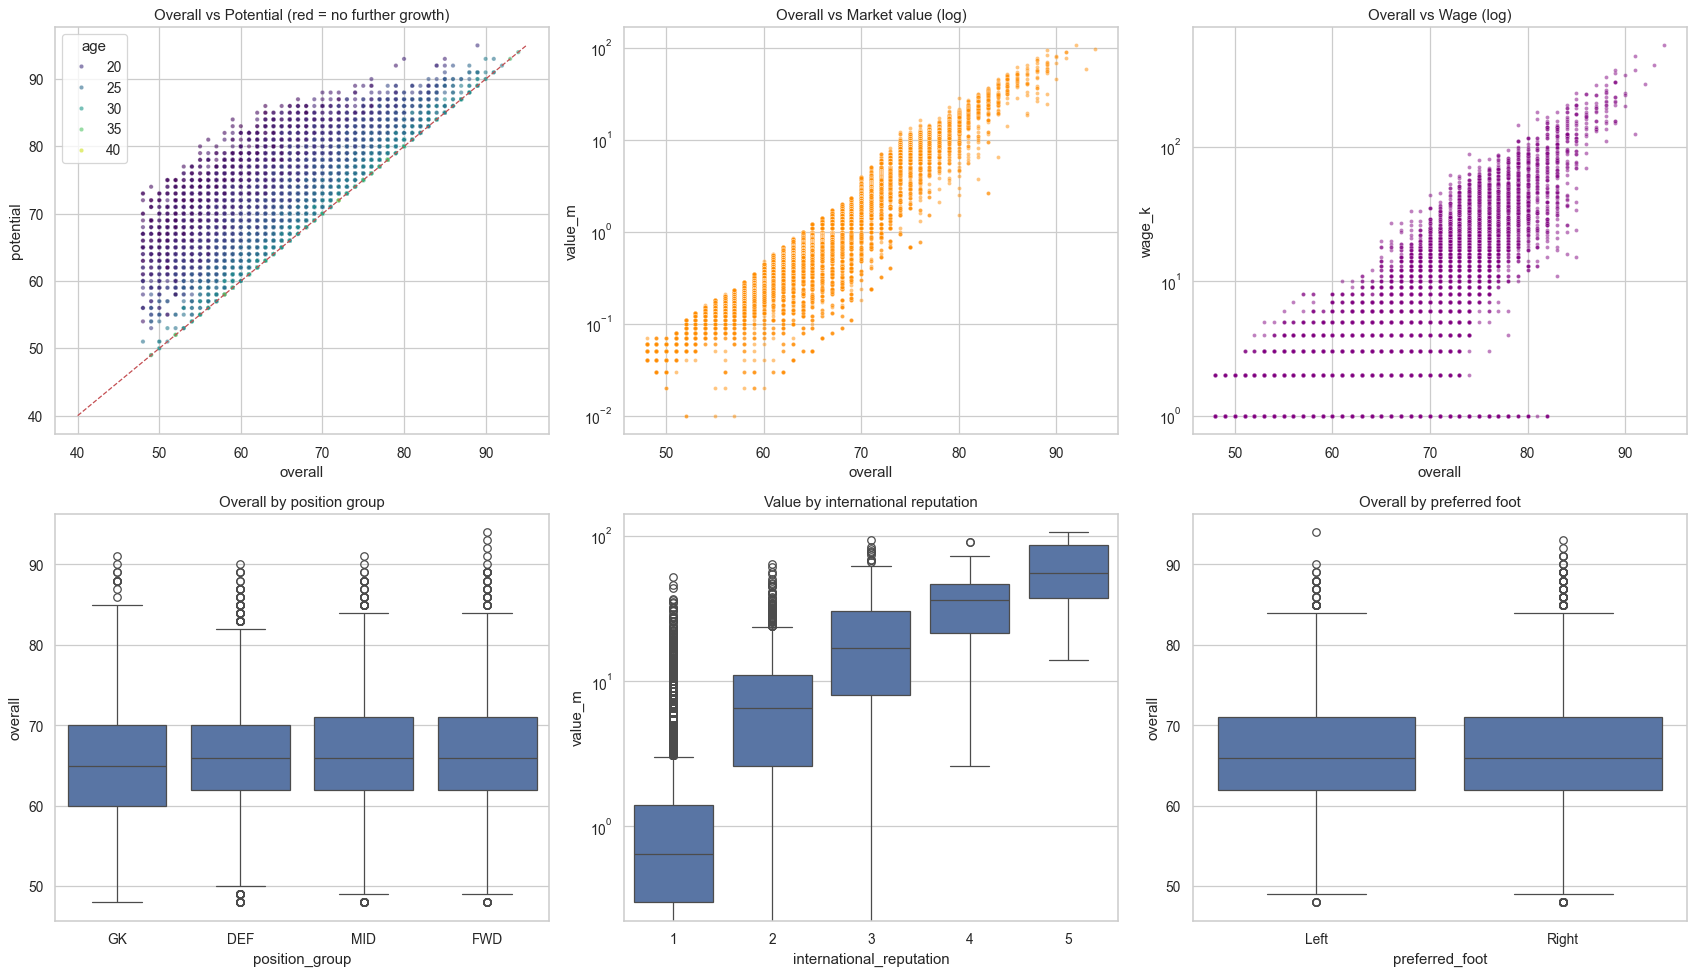

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11)); axes = axes.ravel()
sns.scatterplot(data=df, x='overall', y='potential', hue='age', palette='viridis', s=12, alpha=.6, ax=axes[0])
axes[0].plot([40, 95], [40, 95], 'r--', lw=1); axes[0].set_title('Overall vs Potential (red = no further growth)')
sns.scatterplot(data=df, x='overall', y='value_m', s=10, alpha=.5, ax=axes[1], color='darkorange')
axes[1].set_yscale('log'); axes[1].set_title('Overall vs Market value (log)')
sns.scatterplot(data=df[df.wage_eur > 0], x='overall', y='wage_k', s=10, alpha=.5, ax=axes[2], color='purple')
axes[2].set_yscale('log'); axes[2].set_title('Overall vs Wage (log)')
sns.boxplot(data=df, x='position_group', y='overall', order=['GK', 'DEF', 'MID', 'FWD'], ax=axes[3]); axes[3].set_title('Overall by position group')
sns.boxplot(data=df, x='international_reputation', y='value_m', ax=axes[4]); axes[4].set_yscale('log'); axes[4].set_title('Value by international reputation')
sns.boxplot(data=df, x='preferred_foot', y='overall', ax=axes[5]); axes[5].set_title('Overall by preferred foot')
plt.tight_layout()

Strongest correlates of OVERALL:
reactions       0.86
composure       0.72
potential       0.65
value_m         0.64
wage_k          0.57
shot_power      0.57
vision          0.51
short_passing   0.50

Most-correlated skill pairs (|r| > 0.90):
standing_tackle  sliding_tackle    0.98
interceptions    standing_tackle   0.95
dribbling        ball_control      0.94
interceptions    sliding_tackle    0.93
acceleration     sprint_speed      0.92
marking          standing_tackle   0.92
short_passing    ball_control      0.92
marking          sliding_tackle    0.91
interceptions    marking           0.91
dribbling        positioning       0.90


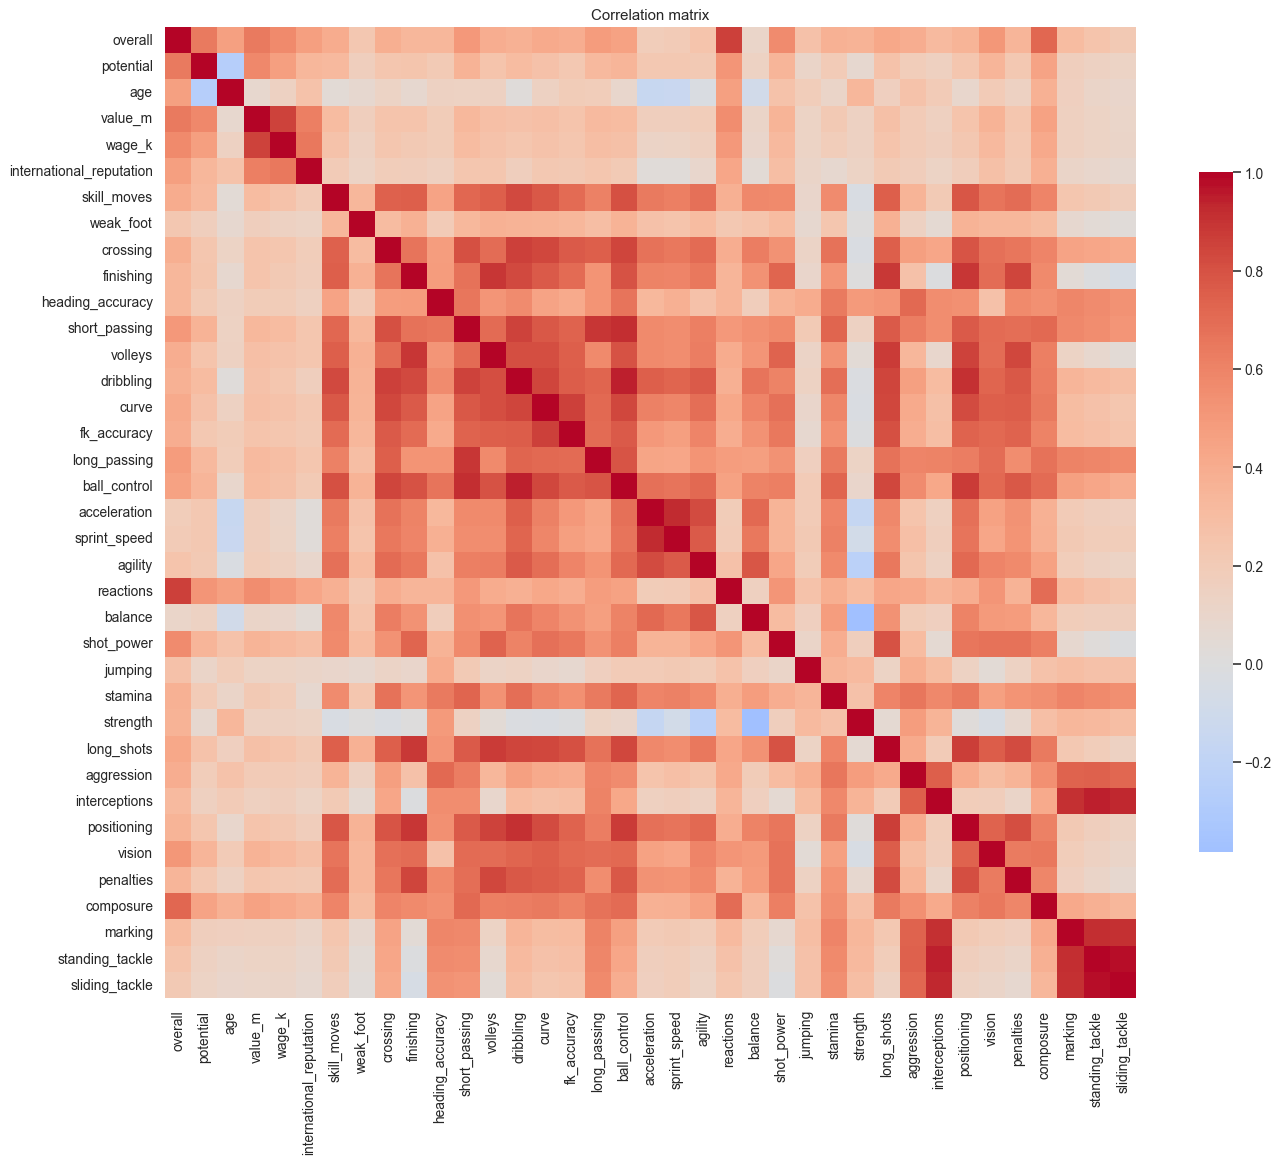

In [12]:
# Correlation structure of the skill attributes + key numerics
corr_cols = ['overall', 'potential', 'age', 'value_m', 'wage_k', 'international_reputation', 'skill_moves', 'weak_foot'] + SKILLS
corr = df[corr_cols].corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=False, square=True, cbar_kws={'shrink': .7})
plt.title('Correlation matrix'); plt.tight_layout()

print('Strongest correlates of OVERALL:')
print(corr['overall'].drop('overall').sort_values(ascending=False).round(2).head(8).to_string())
print('\nMost-correlated skill pairs (|r| > 0.90):')
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print(pairs[pairs.abs() > .9].sort_values(ascending=False).round(2).to_string())

**Take-aways** — `reactions` (r≈0.86) and `potential`, `value`, `wage` and `international_reputation` track `overall` most; ball-skill attributes (`short_passing`, `ball_control`, `dribbling`, `vision`) are strongly inter-correlated (technical block) while defensive attributes (`marking`, tackles, `interceptions`) form their own tightly-linked block (r > 0.9) that is *unrelated or negatively related* to finishing/dribbling. This high collinearity is why **PCA** is applied before clustering (Task 2).

## 1.8 Position-group profile, top players and clubs

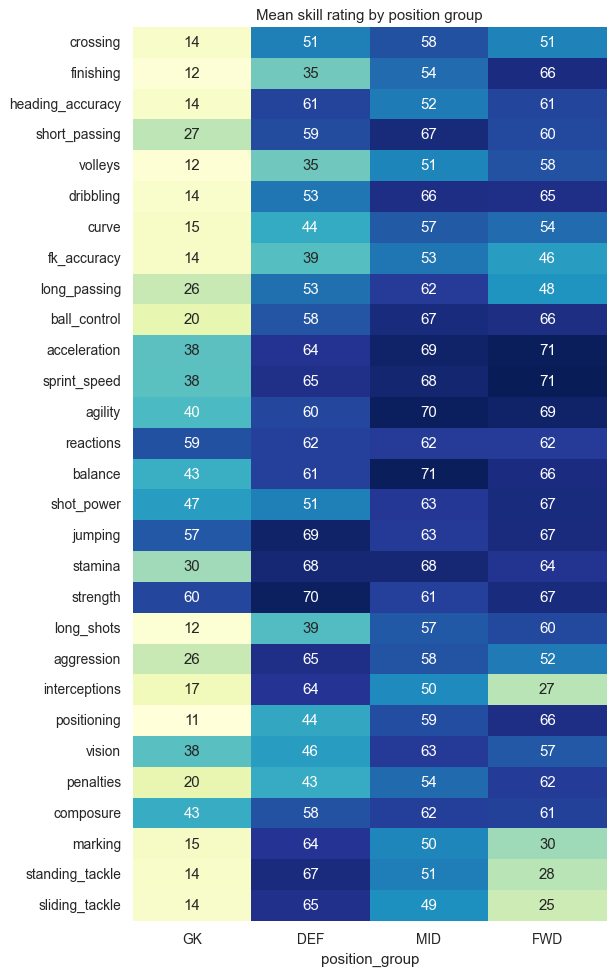

In [13]:
prof = df.groupby('position_group')[SKILLS].mean().T[['GK', 'DEF', 'MID', 'FWD']]
plt.figure(figsize=(7, 11))
sns.heatmap(prof, annot=True, fmt='.0f', cmap='YlGnBu', cbar=False)
plt.title('Mean skill rating by position group'); plt.tight_layout()

In [14]:
print('--- Top 10 by overall ---')
display(df.nlargest(10, 'overall')[['short_name', 'age', 'nationality', 'club', 'primary_position', 'overall', 'potential', 'value_m', 'wage_k']])
print('--- Top 10 young talents (age <= 21) by potential ---')
display(df[df.age <= 21].nlargest(10, 'potential')[['short_name', 'age', 'nationality', 'club', 'primary_position', 'overall', 'potential', 'value_m']])
club = df.groupby('club').agg(players=('overall', 'size'), avg_overall=('overall', 'mean'), total_value_m=('value_m', 'sum'))
club = club[(club.players >= 20) & (club.total_value_m > 0)]   # drops national-team squads (no market value)
print('--- Top 10 clubs by average overall (>=20 players listed) ---')
club.sort_values('avg_overall', ascending=False).head(10)

--- Top 10 by overall ---


,short_name,age,nationality,club,primary_position,overall,potential,value_m,wage_k
0,L. Messi,32,Argentina,FC Barcelona,RW,94,94,95.50,565.00
1,Cristiano Ronaldo,34,Portugal,Juventus,ST,93,93,58.50,405.00
2,Neymar Jr,27,Brazil,Paris Saint-Germain,LW,92,92,105.50,290.00
3,J. Oblak,26,Slovenia,Atlético Madrid,GK,91,93,77.50,125.00
4,E. Hazard,28,Belgium,Real Madrid,LW,91,91,90.00,470.00
5,K. De Bruyne,28,Belgium,Manchester City,CAM,91,91,90.00,370.00
6,M. ter Stegen,27,Germany,FC Barcelona,GK,90,93,67.50,250.00
7,V. van Dijk,27,Netherlands,Liverpool,CB,90,91,78.00,200.00
8,L. Modrić,33,Croatia,Real Madrid,CM,90,90,45.00,340.00
9,M. Salah,27,Egypt,Liverpool,RW,90,90,80.50,240.00


--- Top 10 young talents (age <= 21) by potential ---


,short_name,age,nationality,club,primary_position,overall,potential,value_m
10,K. Mbappé,20,France,Paris Saint-Germain,ST,89,95,93.50
73,M. de Ligt,19,Netherlands,Juventus,CB,85,93,50.00
411,João Félix,19,Portugal,Atlético Madrid,CF,80,93,28.00
74,G. Donnarumma,20,Italy,Milan,GK,85,92,41.50
108,J. Sancho,19,England,Borussia Dortmund,RM,84,92,44.50
109,K. Havertz,20,Germany,Bayer 04 Leverkusen,CAM,84,92,46.00
568,Vinícius Jr.,18,Brazil,Real Madrid,LW,79,92,22.50
1254,P. Foden,19,England,Manchester City,CAM,76,90,16.50
160,T. Alexander-Arnold,20,England,Liverpool,RB,83,89,32.00
161,L. Jović,21,Serbia,Real Madrid,ST,83,89,36.50


--- Top 10 clubs by average overall (>=20 players listed) ---


,players,avg_overall,total_value_m
club,,,
FC Bayern München,23,81.30,688.77
Real Madrid,33,80.12,897.85
Juventus,33,80.06,735.48
FC Barcelona,33,78.36,869.30
Bayer 04 Leverkusen,25,77.28,359.40
Chelsea,33,77.06,504.97
Manchester City,33,77.00,845.75
Napoli,31,76.87,518.27
Manchester United,33,76.85,501.68


In [15]:
# Single-version version of the "Messi vs Ronaldo" idea in the brief
cmp_cols = ['overall', 'potential', 'pace_proxy', 'finishing', 'dribbling', 'ball_control', 'short_passing', 'shot_power',
            'sprint_speed', 'acceleration', 'stamina', 'strength', 'vision', 'composure', 'penalties']
df['pace_proxy'] = (df.acceleration + df.sprint_speed) / 2
two = df[df.short_name.isin(['L. Messi', 'Cristiano Ronaldo'])].set_index('short_name')[cmp_cols].T
two['diff (Messi-Ronaldo)'] = two['L. Messi'] - two['Cristiano Ronaldo']
two

short_name,L. Messi,Cristiano Ronaldo,diff (Messi-Ronaldo)
overall,94.00,93.00,1.00
potential,94.00,93.00,1.00
pace_proxy,87.50,90.00,-2.50
finishing,95.00,94.00,1.00
dribbling,97.00,89.00,8.00
ball_control,96.00,92.00,4.00
short_passing,92.00,83.00,9.00
shot_power,86.00,95.00,-9.00
sprint_speed,84.00,91.00,-7.00
acceleration,91.00,89.00,2.00


## 1.9 Key insights from the analysis (Task 1)
1. **Data quality is good**: no duplicates; every missing value is *structural* (GKs have no outfield composites, free agents have no contract, tags/traits are optional) rather than random.
2. **Money is hugely unequal**: value and wage are heavy-tailed (skew ≫ 1) and grow roughly exponentially with `overall` — the jump from 80 → 90 overall multiplies value many times over.
3. **`overall` is driven by mental/technical attributes** such as reactions, composure and passing rather than raw physical ones.
4. **~3 of 4 players are right-footed**; most players are listed with *medium/medium* work-rate.
5. **Position groups have clearly distinct skill signatures** (heatmap) — GKs, defenders, midfielders and forwards differ markedly, which motivates the clustering in Task 2.
6. The data is a **single snapshot (FIFA 20)**, so inferences about age/ageing in Task 3 are cross-sectional (different players at each age), not individual career trajectories.

---
# TASK 2 — Clustering football players by their skill sets
**Goal:** group players using their *whole skill-set*, **not** their reputation. As the brief says, `overall`, `potential`, `position` (and the positional ratings) are **excluded from the model** and only used afterwards to interpret the clusters.

**Features used (39):** 29 outfield skills, 5 goalkeeping skills, `height_cm`, `preferred_foot_enc`, `weak_foot`, `atk_work_rate`, `def_work_rate`.

Pipeline: standardise → PCA (≥ 90 % variance, removes collinearity) → choose *k* with several internal indices → K-Means → profile.

**Design decision:** a first global run shows goalkeepers are so different that they dominate the structure (see 2.1). I therefore use a **two-stage approach** — goalkeepers form their own cluster, then outfield players are clustered on their skills (2.2).

Feature matrix: (18278, 39)
11 components keep 90.4% of the variance


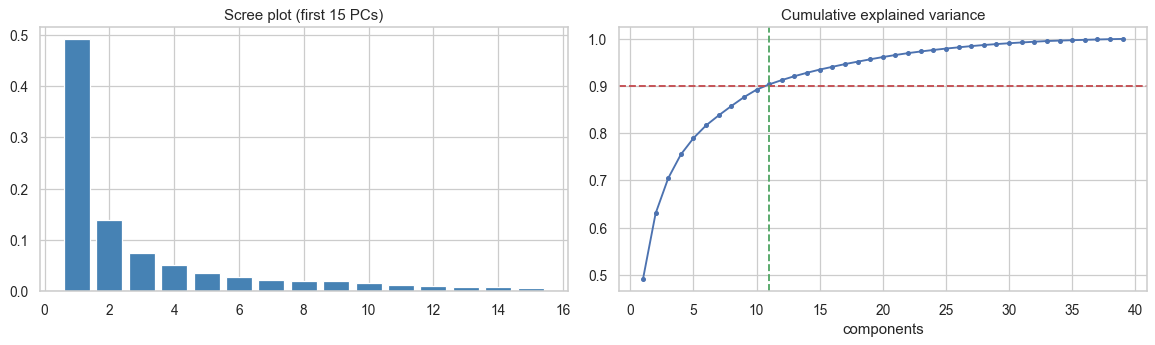

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

CLUSTER_FEATURES = SKILLS + GK_SKILLS + ['height_cm', 'preferred_foot_enc', 'weak_foot', 'atk_work_rate', 'def_work_rate']
X = df[CLUSTER_FEATURES].copy()
assert X.isna().sum().sum() == 0
print('Feature matrix:', X.shape)

scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)

pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum >= 0.90)) + 1
print(f'{n_comp} components keep {cum[n_comp-1]*100:.1f}% of the variance')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(1, 16), pca_full.explained_variance_ratio_[:15], color='steelblue'); ax[0].set_title('Scree plot (first 15 PCs)')
ax[1].plot(range(1, len(cum) + 1), cum, marker='o', ms=3); ax[1].axhline(.9, color='r', ls='--'); ax[1].axvline(n_comp, color='g', ls='--')
ax[1].set_title('Cumulative explained variance'); ax[1].set_xlabel('components')
plt.tight_layout()

pca = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit(X_scaled)
X_pca = pca.transform(X_scaled)

### 2.1 Stage 1 — global k-sweep (all players)

In [17]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    rows.append(dict(k=k, inertia=km.inertia_,
                     silhouette=silhouette_score(X_pca, km.labels_, sample_size=6000, random_state=RANDOM_STATE),
                     davies_bouldin=davies_bouldin_score(X_pca, km.labels_)))
kdf = pd.DataFrame(rows).set_index('k'); display(kdf)

km2 = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
print('k=2 split vs goalkeeper flag:'); display(pd.crosstab(km2.labels_, df.position_group == 'GK', rownames=['cluster'], colnames=['is GK']))

,inertia,silhouette,davies_bouldin
k,,,
2,"367,561.77",0.54,0.59
3,"281,154.14",0.27,1.27
4,"235,919.02",0.26,1.34
5,"215,361.06",0.24,1.45
6,"201,269.05",0.21,1.53
7,"190,007.10",0.21,1.51
8,"180,540.99",0.21,1.53


k=2 split vs goalkeeper flag:


is GK,False,True
cluster,,
0,16241,0
1,1,2036


With *k = 2* the silhouette is very high (≈0.54) — but the split is simply **goalkeepers vs. everybody else**; beyond that the silhouette collapses to ≈0.25. The goalkeeper group is perfectly separable and uninteresting to sub-divide, so it is fixed as its own cluster and the *interesting* structure is searched among the **16,242 outfield players**.

### 2.2 Stage 2 — clustering the outfield players

Outfield players: 16,242 | PCA components for 90% variance: 15


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"373,087.12",0.22,1.62,"5,530.29"
3,"312,772.48",0.20,1.63,"4,863.92"
4,"282,887.63",0.17,1.66,"4,156.76"
5,"262,981.53",0.15,1.75,"3,660.61"
6,"247,521.18",0.15,1.70,"3,314.03"
7,"233,796.11",0.15,1.69,"3,082.48"
8,"223,809.50",0.14,1.72,"2,863.33"


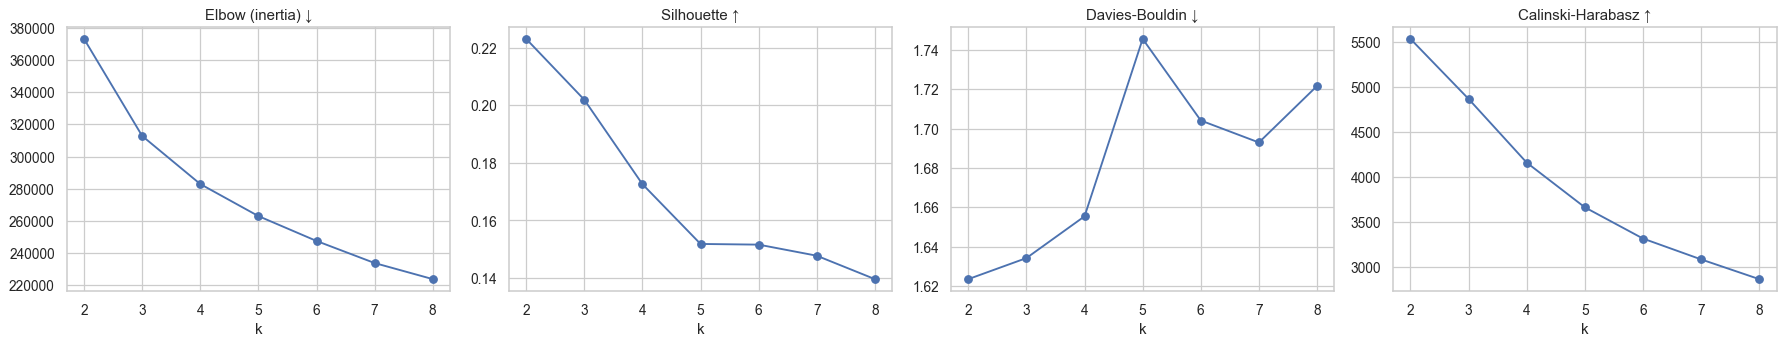

In [18]:
out_mask = (df.position_group != 'GK').values
out_df = df[out_mask].copy()
OUT_FEATURES = SKILLS + ['height_cm', 'preferred_foot_enc', 'weak_foot', 'atk_work_rate', 'def_work_rate']   # GK skills are noise here

scaler_out = StandardScaler().fit(out_df[OUT_FEATURES])
Xo = scaler_out.transform(out_df[OUT_FEATURES])
pca_out = PCA(n_components=0.90, random_state=RANDOM_STATE).fit(Xo)
Xo_pca = pca_out.transform(Xo)
print(f'Outfield players: {len(out_df):,} | PCA components for 90% variance: {pca_out.n_components_}')

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xo_pca)
    rows.append(dict(k=k, inertia=km.inertia_,
                     silhouette=silhouette_score(Xo_pca, km.labels_, sample_size=6000, random_state=RANDOM_STATE),
                     davies_bouldin=davies_bouldin_score(Xo_pca, km.labels_),
                     calinski_harabasz=calinski_harabasz_score(Xo_pca, km.labels_)))
kdf_out = pd.DataFrame(rows).set_index('k'); display(kdf_out)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (c, t) in zip(axes, [('inertia', 'Elbow (inertia) ↓'), ('silhouette', 'Silhouette ↑'),
                             ('davies_bouldin', 'Davies-Bouldin ↓'), ('calinski_harabasz', 'Calinski-Harabasz ↑')]):
    ax.plot(kdf_out.index, kdf_out[c], marker='o'); ax.set_title(t); ax.set_xlabel('k')
plt.tight_layout()

**Choosing k.** Silhouette / Davies-Bouldin favour small k (k = 2 or 3) because the data is a *continuum* of skills rather than well-separated blobs. At **k = 3** the split is pure "defenders / attackers / midfield"; at **k = 4** a fourth group appears (a small, high-rated group of creative attackers and playmakers) while every cluster keeps a clear football meaning and a sensible size, and the elbow flattens from here. I therefore take **k = 4 outfield clusters (+1 goalkeeper cluster = 5 archetypes)**, a compromise between statistical compactness and usefulness for scouts.

In [19]:
K_OUT = 4
km_out = KMeans(n_clusters=K_OUT, n_init=20, random_state=RANDOM_STATE).fit(Xo_pca)
out_df['raw_cluster'] = km_out.labels_

# --- naming rule based on the positional make-up of each cluster ---
share = pd.crosstab(out_df.raw_cluster, out_df.primary_position, normalize='index')
fwd_share = pd.crosstab(out_df.raw_cluster, out_df.position_group, normalize='index')['FWD']
means = out_df.groupby('raw_cluster').overall.mean()
names = {}
names[share['CB'].idxmax()] = 'Physical centre-backs'
rest = [c for c in share.index if c not in names]
names[fwd_share[rest].idxmax()] = 'Strikers & wide forwards'
rest = [c for c in share.index if c not in names]
names[means[rest].idxmax()] = 'Elite creative attackers & playmakers'
rest = [c for c in share.index if c not in names]
names[rest[0]] = 'Defensive all-rounders (DM / full-back / top CB)'
out_df['cluster_name'] = out_df.raw_cluster.map(names)
df['cluster_name'] = 'Goalkeepers'
df.loc[out_df.index, 'cluster_name'] = out_df.cluster_name
order = ['Goalkeepers', 'Physical centre-backs', 'Defensive all-rounders (DM / full-back / top CB)', 'Strikers & wide forwards', 'Elite creative attackers & playmakers']

print('Outfield silhouette (full data, sampled):', round(silhouette_score(Xo_pca, km_out.labels_, sample_size=8000, random_state=RANDOM_STATE), 3))
print(df.cluster_name.value_counts().reindex(order).to_string())
print('\nCluster vs primary position (row %):')
display((pd.crosstab(df.cluster_name, df.primary_position, normalize='index') * 100).round(0).astype(int).reindex(order))

Outfield silhouette (full data, sampled): 0.172
cluster_name
Goalkeepers                                         2036
Physical centre-backs                               3449
Defensive all-rounders (DM / full-back / top CB)    4808
Strikers & wide forwards                            4398
Elite creative attackers & playmakers               3587

Cluster vs primary position (row %):


primary_position,CAM,CB,CDM,CF,CM,GK,LB,LM,LW,LWB,RB,RM,RW,RWB,ST
cluster_name,,,,,,,,,,,,,,,
Goalkeepers,0,0,0,0,0,100,0,0,0,0,0,0,0,0,0
Physical centre-backs,0,70,7,0,4,0,9,0,0,0,10,0,0,0,0
Defensive all-rounders (DM / full-back / top CB),1,16,21,0,21,0,17,2,0,1,17,2,0,1,1
Strikers & wide forwards,13,0,0,1,8,0,1,13,5,0,1,13,5,0,41
Elite creative attackers & playmakers,15,0,4,2,20,0,4,11,4,0,4,10,4,0,21


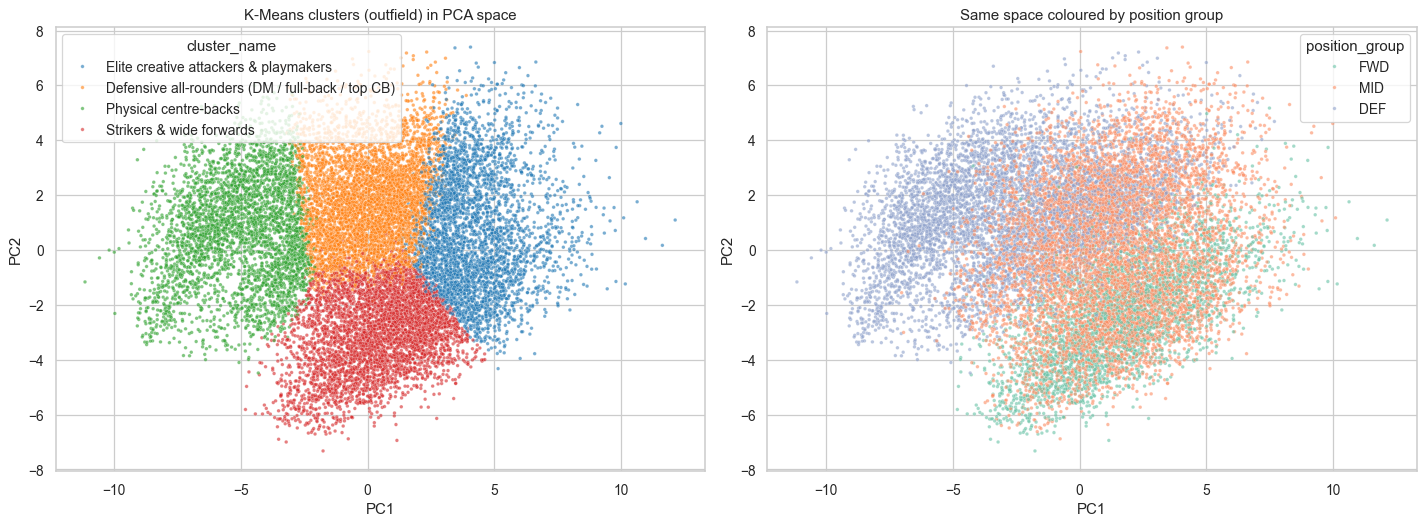

In [20]:
# 2-D picture of the outfield clusters (first two principal components)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=Xo_pca[:, 0], y=Xo_pca[:, 1], hue=out_df.cluster_name, palette='tab10', s=8, alpha=.6, ax=axes[0])
axes[0].set_title('K-Means clusters (outfield) in PCA space'); axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
sns.scatterplot(x=Xo_pca[:, 0], y=Xo_pca[:, 1], hue=out_df.position_group, palette='Set2', s=8, alpha=.6, ax=axes[1])
axes[1].set_title('Same space coloured by position group'); axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.tight_layout()

,players,avg_age,avg_overall,avg_potential,median_value_m,median_wage_k,avg_height
cluster_name,,,,,,,
Goalkeepers,2036,26.27,64.80,70.09,0.40,2.00,188.44
Physical centre-backs,3449,24.34,62.83,69.56,0.40,2.00,184.74
Defensive all-rounders (DM / full-back / top CB),4808,26.06,67.69,71.82,0.80,4.00,180.35
Strikers & wide forwards,4398,23.08,62.25,70.13,0.47,2.00,178.96
Elite creative attackers & playmakers,3587,27.29,73.31,75.66,3.90,13.00,178.40


Goalkeepers: J. Oblak (GK), M. ter Stegen (GK), Alisson (GK), De Gea (GK), Ederson (GK), T. Courtois (GK)
Physical centre-backs: N. Süle (CB), K. Manolas (CB), J. Tah (CB), S. Savić (CB), S. Coates (CB), W. Orban (CB)
Defensive all-rounders (DM / full-back / top CB): V. van Dijk (CB), K. Koulibaly (CB), G. Chiellini (CB), Piqué (CB), D. Godín (CB), A. Laporte (CB)
Strikers & wide forwards: M. Kean (ST), T. Abraham (ST), R. Inglese (ST), L. Ajorque (ST), V. Muriqi (ST), L. Tawamba (ST)
Elite creative attackers & playmakers: L. Messi (RW), Cristiano Ronaldo (ST), Neymar Jr (LW), E. Hazard (LW), K. De Bruyne (CAM), L. Modrić (CM)


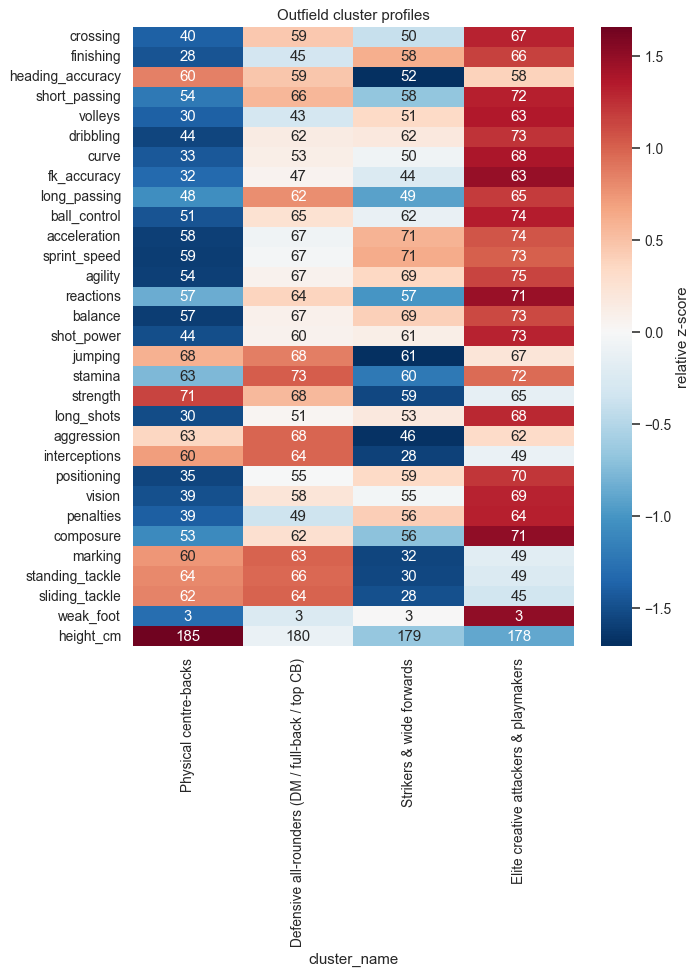

In [21]:
# Cluster profiles: mean skill rating (cell) and relative strength (colour)
prof = out_df.groupby('cluster_name')[SKILLS + ['weak_foot', 'height_cm']].mean().reindex(order[1:])
z = (prof - prof.mean()) / prof.std(ddof=0)
plt.figure(figsize=(8, 11))
sns.heatmap(z.T, cmap='RdBu_r', center=0, annot=prof.T.round(0), fmt='.0f', cbar_kws={'label': 'relative z-score'})
plt.title('Outfield cluster profiles'); plt.tight_layout()

summary_c = df.groupby('cluster_name').agg(players=('overall', 'size'), avg_age=('age', 'mean'), avg_overall=('overall', 'mean'),
                                            avg_potential=('potential', 'mean'), median_value_m=('value_m', 'median'),
                                            median_wage_k=('wage_k', 'median'), avg_height=('height_cm', 'mean')).reindex(order)
display(summary_c)
for c in order:
    top = df[df.cluster_name == c].nlargest(6, 'overall')
    print(f'{c}: ' + ', '.join(f'{n} ({p})' for n, p in zip(top.short_name, top.primary_position)))

---
# TASK 3 — Guided questions
## Q1. Top-10 countries with the most players

,country,players,share_%,avg_overall,players_80+,players_85+
rank,,,,,,
1,England,1667,9.12,63.25,26,2
2,Germany,1216,6.65,65.94,43,9
3,Spain,1035,5.66,69.95,92,14
4,France,984,5.38,67.42,57,12
5,Argentina,886,4.85,69.12,37,7
6,Brazil,824,4.51,71.16,56,14
7,Italy,732,4.00,67.66,33,6
8,Colombia,591,3.23,65.68,8,1
9,Japan,453,2.48,63.69,1,0


Top-10 countries together supply 8,804 players = 48.2% of all players (from 162 nationalities).


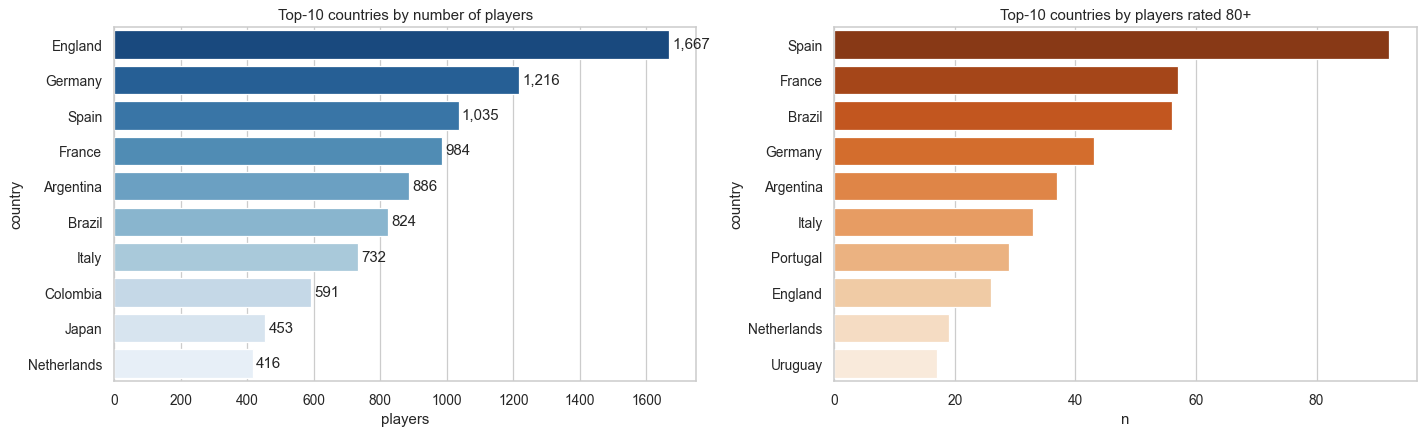

In [22]:
top10 = df.nationality.value_counts().head(10).rename_axis('country').reset_index(name='players')
top10.insert(0, 'rank', range(1, 11))
top10['share_%'] = top10.players / len(df) * 100
top10['avg_overall'] = top10.country.map(df.groupby('nationality').overall.mean())
top10['players_80+'] = top10.country.map(df[df.overall >= 80].nationality.value_counts()).fillna(0).astype(int)
top10['players_85+'] = top10.country.map(df[df.overall >= 85].nationality.value_counts()).fillna(0).astype(int)
display(top10.set_index('rank'))
print(f"Top-10 countries together supply {top10.players.sum():,} players = {top10.players.sum()/len(df)*100:.1f}% of all players (from {df.nationality.nunique()} nationalities).")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=top10, y='country', x='players', ax=axes[0], palette='Blues_r')
for i, v in enumerate(top10.players): axes[0].text(v + 10, i, f'{v:,}', va='center')
axes[0].set_title('Top-10 countries by number of players')
elite = df[df.overall >= 80].nationality.value_counts().head(10).rename_axis('country').reset_index(name='n')
sns.barplot(data=elite, y='country', x='n', ax=axes[1], palette='Oranges_r'); axes[1].set_title('Top-10 countries by players rated 80+')
plt.tight_layout()

## Q2. Distribution of overall rating vs. age — when does a player stop improving?

,n,mean_overall,p90_overall,mean_potential,gap(pot-overall),yoy_change
age,,,,,,
17,229,55.79,63.00,74.56,18.77,-0.63
18,640,57.27,64.00,73.86,16.59,1.49
19,1011,59.51,67.00,73.95,14.45,2.23
20,1247,61.22,69.00,73.38,12.16,1.71
21,1375,63.26,72.00,73.41,10.15,2.04
22,1446,64.61,73.00,73.02,8.41,1.35
23,1358,66.04,74.00,72.90,6.86,1.43
24,1296,66.98,75.00,72.26,5.28,0.94
25,1319,67.90,75.00,71.63,3.72,0.93


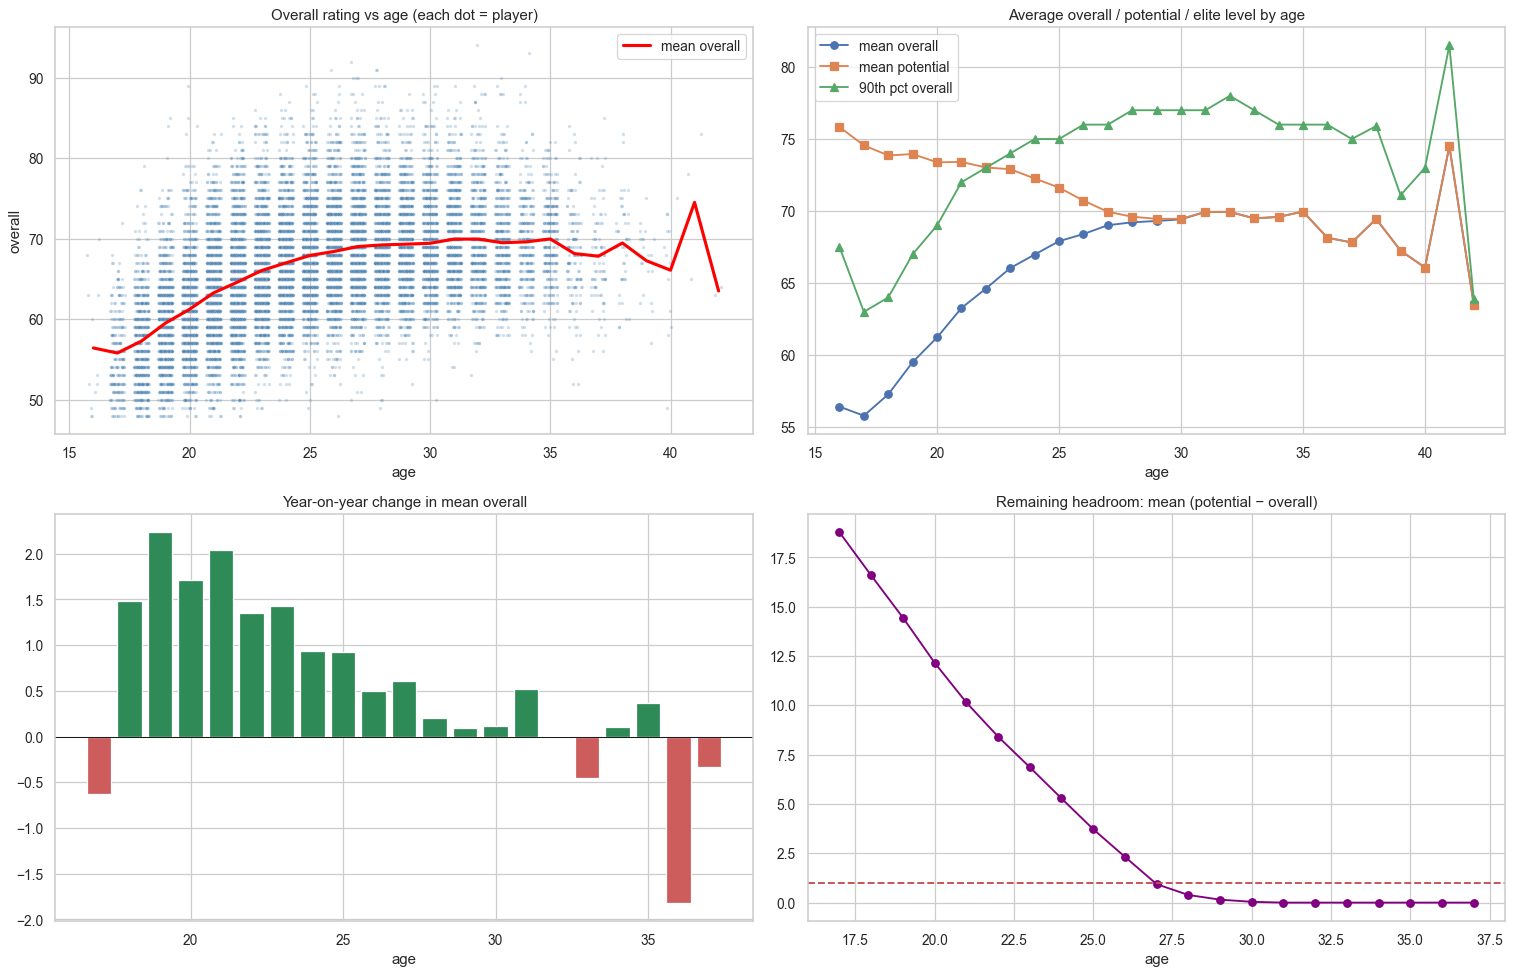

In [23]:
age_stats = df.groupby('age').agg(n=('overall', 'size'), mean_overall=('overall', 'mean'), p90_overall=('overall', lambda s: s.quantile(.9)),
                                   mean_potential=('potential', 'mean')).reset_index()
age_stats['gap(pot-overall)'] = age_stats.mean_potential - age_stats.mean_overall
age_stats['yoy_change'] = age_stats.mean_overall.diff()

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
sns.scatterplot(data=df, x=df.age + np.random.RandomState(1).uniform(-.3, .3, len(df)), y='overall', s=7, alpha=.25, ax=axes[0, 0], color='steelblue')
axes[0, 0].plot(age_stats.age, age_stats.mean_overall, color='red', lw=2.5, label='mean overall'); axes[0, 0].legend()
axes[0, 0].set_title('Overall rating vs age (each dot = player)'); axes[0, 0].set_xlabel('age')
axes[0, 1].plot(age_stats.age, age_stats.mean_overall, marker='o', label='mean overall')
axes[0, 1].plot(age_stats.age, age_stats.mean_potential, marker='s', label='mean potential')
axes[0, 1].plot(age_stats.age, age_stats.p90_overall, marker='^', label='90th pct overall')
axes[0, 1].legend(); axes[0, 1].set_title('Average overall / potential / elite level by age'); axes[0, 1].set_xlabel('age')
sub = age_stats[age_stats.n >= 50]
axes[1, 0].bar(sub.age, sub.yoy_change, color=np.where(sub.yoy_change >= 0, 'seagreen', 'indianred'))
axes[1, 0].axhline(0, color='k', lw=.8); axes[1, 0].set_title('Year-on-year change in mean overall'); axes[1, 0].set_xlabel('age')
axes[1, 1].plot(sub.age, sub['gap(pot-overall)'], marker='o', color='purple'); axes[1, 1].axhline(1, color='r', ls='--')
axes[1, 1].set_title('Remaining headroom: mean (potential − overall)'); axes[1, 1].set_xlabel('age')
plt.tight_layout()

display(age_stats[(age_stats.n >= 50)].set_index('age').round(2))

In [24]:
sub = age_stats[age_stats.n >= 50].set_index('age')
peak_mean = sub.mean_overall.idxmax()
peak_p90 = sub.p90_overall.idxmax()
headroom_gone = sub[(sub.index >= 20) & (sub['gap(pot-overall)'] <= 1)].index.min()
growth_stalls = sub[(sub.index >= 20) & (sub.yoy_change < 0.5)].index.min()
print(f'Average growth falls below +0.5 overall points/yr first at age : {growth_stalls}')
print(f'Average potential-minus-overall gap closes to <= 1 point at age: {headroom_gone}')
print(f'Age of highest MEAN overall (n>=50)                            : {peak_mean}')
print(f'Age of highest 90th-percentile overall                         : {peak_p90}')
print('\nMean overall at selected ages:', sub.loc[[20, 22, 24, 26, 28, 30, 32, 34], 'mean_overall'].round(1).to_dict())

Average growth falls below +0.5 overall points/yr first at age : 26
Average potential-minus-overall gap closes to <= 1 point at age: 27
Age of highest MEAN overall (n>=50)                            : 35
Age of highest 90th-percentile overall                         : 32

Mean overall at selected ages: {20: 61.2, 22: 64.6, 24: 67.0, 26: 68.4, 28: 69.2, 30: 69.4, 32: 69.9, 34: 69.6}


## Q3. Which offensive position is paid the most — striker, right-winger or left-winger?
Players are classified by their **primary listed position** (`ST`, `RW`, `LW`); only players with a contract (`wage_eur > 0`) are used. Wages are heavily skewed, so medians, log-scale plots and non-parametric tests are used.

,players,mean_wage_k,median_wage_k,p90_wage_k,mean_value_m,avg_overall,avg_age
primary_position,,,,,,,
ST,2552,10.27,4.00,26.00,2.72,66.39,25.22
RW,367,15.93,4.00,35.00,4.24,67.04,23.77
LW,375,14.15,4.00,33.00,4.04,66.92,23.46


Kruskal-Wallis on wage: H = 0.30, p = 0.8608
  ST vs RW: Mann-Whitney p = 0.9968  (Bonferroni threshold 0.0167)
  ST vs LW: Mann-Whitney p = 0.5872  (Bonferroni threshold 0.0167)
  RW vs LW: Mann-Whitney p = 0.6826  (Bonferroni threshold 0.0167)


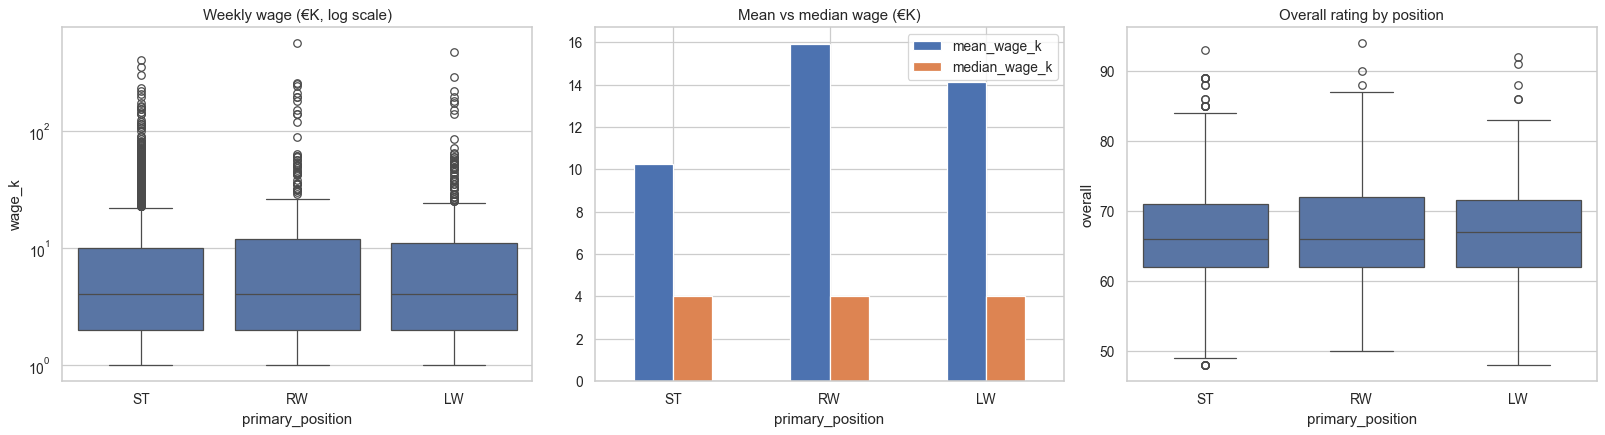

In [25]:
att = df[df.primary_position.isin(['ST', 'RW', 'LW']) & (df.wage_eur > 0)].copy()
agg = att.groupby('primary_position').agg(players=('wage_eur', 'size'), mean_wage_k=('wage_k', 'mean'), median_wage_k=('wage_k', 'median'),
                                           p90_wage_k=('wage_k', lambda s: s.quantile(.9)), mean_value_m=('value_m', 'mean'),
                                           avg_overall=('overall', 'mean'), avg_age=('age', 'mean')).loc[['ST', 'RW', 'LW']]
display(agg)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=att, x='primary_position', y='wage_k', order=['ST', 'RW', 'LW'], ax=axes[0]); axes[0].set_yscale('log'); axes[0].set_title('Weekly wage (€K, log scale)')
agg[['mean_wage_k', 'median_wage_k']].plot.bar(ax=axes[1], rot=0); axes[1].set_title('Mean vs median wage (€K)')
sns.boxplot(data=att, x='primary_position', y='overall', order=['ST', 'RW', 'LW'], ax=axes[2]); axes[2].set_title('Overall rating by position')
plt.tight_layout()

# Is the difference statistically significant?
groups = [att.loc[att.primary_position == p, 'wage_eur'] for p in ['ST', 'RW', 'LW']]
H, p = stats.kruskal(*groups); print(f'Kruskal-Wallis on wage: H = {H:.2f}, p = {p:.4f}')
for a, b in [('ST', 'RW'), ('ST', 'LW'), ('RW', 'LW')]:
    u, pv = stats.mannwhitneyu(att.loc[att.primary_position == a, 'wage_eur'], att.loc[att.primary_position == b, 'wage_eur'])
    print(f'  {a} vs {b}: Mann-Whitney p = {pv:.4f}  (Bonferroni threshold 0.0167)')

In [26]:
# Fair comparison: do positions still differ once quality is accounted for?
from sklearn.linear_model import LinearRegression
Z = pd.DataFrame({'overall': att.overall, 'age': att.age, 'intl_rep': att.international_reputation,
                  'is_RW': (att.primary_position == 'RW').astype(int), 'is_LW': (att.primary_position == 'LW').astype(int)})
lr = LinearRegression().fit(Z, np.log(att.wage_eur))
eff = pd.Series(np.expm1(lr.coef_), index=Z.columns) * 100
print('Wage premium (%) per +1 of each variable, holding the others fixed (ST is the baseline):')
print(eff.round(1).to_string(), f'\nR² = {lr.score(Z, np.log(att.wage_eur)):.2f}')

print('\nMedian wage (€K) among players rated >= 75:')
print(att[att.overall >= 75].groupby('primary_position').agg(n=('wage_k', 'size'), median_wage_k=('wage_k', 'median'), mean_wage_k=('wage_k', 'mean')).loc[['ST', 'RW', 'LW']])

Wage premium (%) per +1 of each variable, holding the others fixed (ST is the baseline):
overall    15.30
age        -2.10
intl_rep   38.50
is_RW      -6.50
is_LW      -4.10 
R² = 0.69

Median wage (€K) among players rated >= 75:
                    n  median_wage_k  mean_wage_k
primary_position                                 
ST                297          32.00        45.23
RW                 49          43.00        79.12
LW                 57          39.00        61.98


---
# REPORT A — Model comparison & recommendation for production
Two complementary model families are benchmarked:

* **A1 – Unsupervised:** which clustering algorithm gives the best skill-based player archetypes?
* **A2 – Supervised:** can a player's on-pitch role (GK / DEF / MID / FWD) be predicted from skills alone? This validates that the skill space really contains role information and gives a deployable model for classifying/scouting new players.

## A1. Clustering algorithms (outfield players, same random 6,000-player benchmark sample, k = 4)

In [27]:
from sklearn.cluster import MiniBatchKMeans, AgglomerativeClustering, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(Xo_pca), 6000, replace=False)
Xs, ys = Xo_pca[idx], out_df.position_group.values[idx]

algos = {'K-Means': KMeans(K_OUT, n_init=20, random_state=RANDOM_STATE),
         'MiniBatch K-Means': MiniBatchKMeans(K_OUT, n_init=20, random_state=RANDOM_STATE),
         'Agglomerative (Ward)': AgglomerativeClustering(K_OUT, linkage='ward'),
         'Gaussian Mixture': GaussianMixture(K_OUT, covariance_type='full', n_init=3, random_state=RANDOM_STATE),
         'Birch': Birch(n_clusters=K_OUT)}
rows = []
for name, m in algos.items():
    t = time.time(); lab = m.fit_predict(Xs); dt = time.time() - t
    sizes = np.bincount(lab); 
    rows.append(dict(model=name, silhouette=silhouette_score(Xs, lab), davies_bouldin=davies_bouldin_score(Xs, lab),
                     calinski_harabasz=calinski_harabasz_score(Xs, lab), ARI_vs_position=adjusted_rand_score(ys, lab),
                     NMI_vs_position=normalized_mutual_info_score(ys, lab), smallest_cluster_pct=sizes.min() / len(lab) * 100, seconds=dt))
cl_res = pd.DataFrame(rows).set_index('model').round(3)
print(cl_res.to_string(float_format=lambda x: f'{x:.3f}'))

                      silhouette  davies_bouldin  calinski_harabasz  ARI_vs_position  NMI_vs_position  smallest_cluster_pct  seconds
model                                                                                                                               
K-Means                    0.172           1.670           1526.200            0.218            0.300                20.750    0.217
MiniBatch K-Means          0.161           1.667           1495.375            0.202            0.283                16.350    0.178
Agglomerative (Ward)       0.158           1.919           1255.049            0.281            0.343                12.467    1.222
Gaussian Mixture           0.058           3.678            624.889            0.240            0.334                12.433    3.042
Birch                      0.139           1.776           1229.107            0.225            0.308                13.983    1.744


### A2. Supervised models — predicting position group from skills
80/20 stratified hold-out split; hyper-parameters kept sensible rather than heavily tuned; 3-fold CV on the training part.

In [28]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

Xc, yc = df[CLUSTER_FEATURES], df.position_group
X_tr, X_te, y_tr, y_te = train_test_split(Xc, yc, test_size=.2, stratify=yc, random_state=RANDOM_STATE)
print('Train / test sizes:', X_tr.shape[0], X_te.shape[0])

models = {'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
          'KNN (k=15)': make_pipeline(StandardScaler(), KNeighborsClassifier(15)),
          'SVM (RBF)': make_pipeline(StandardScaler(), SVC(C=3, random_state=RANDOM_STATE)),
          'Random Forest': RandomForestClassifier(300, n_jobs=-1, random_state=RANDOM_STATE),
          'Hist. Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE)}
skf = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, m in models.items():
    t = time.time(); cv = cross_val_score(m, X_tr, y_tr, cv=skf, scoring='f1_macro', n_jobs=-1)
    m.fit(X_tr, y_tr); fit_t = time.time() - t
    t = time.time(); pred = m.predict(X_te); pred_t = (time.time() - t) / len(X_te) * 1000
    fitted[name] = m
    rows.append(dict(model=name, cv_macroF1=cv.mean(), cv_std=cv.std(), test_accuracy=accuracy_score(y_te, pred),
                     test_macroF1=f1_score(y_te, pred, average='macro'), train_seconds=fit_t, predict_ms_per_player=pred_t))
sup_res = pd.DataFrame(rows).set_index('model').sort_values('test_macroF1', ascending=False).round(4)
print(sup_res.to_string(float_format=lambda x: f'{x:.4f}'))

Train / test sizes: 14622 3656
                         cv_macroF1  cv_std  test_accuracy  test_macroF1  train_seconds  predict_ms_per_player
model                                                                                                         
SVM (RBF)                    0.9134  0.0019         0.9018        0.9103         7.9912                 0.2505
Hist. Gradient Boosting      0.9127  0.0015         0.8999        0.9089         4.1696                 0.0062
Random Forest                0.9103  0.0005         0.8944        0.9050         7.6631                 0.0257
Logistic Regression          0.9102  0.0014         0.8925        0.9047         5.3259                 0.0038
KNN (k=15)                   0.8912  0.0006         0.8725        0.8874         5.5827                 0.0562


Best model on hold-out macro-F1: SVM (RBF) 

              precision    recall  f1-score   support

         DEF      0.941     0.945     0.943      1188
         FWD      0.880     0.775     0.824       688
          GK      1.000     1.000     1.000       407
         MID      0.851     0.899     0.874      1373

    accuracy                          0.902      3656
   macro avg      0.918     0.905     0.910      3656
weighted avg      0.902     0.902     0.901      3656



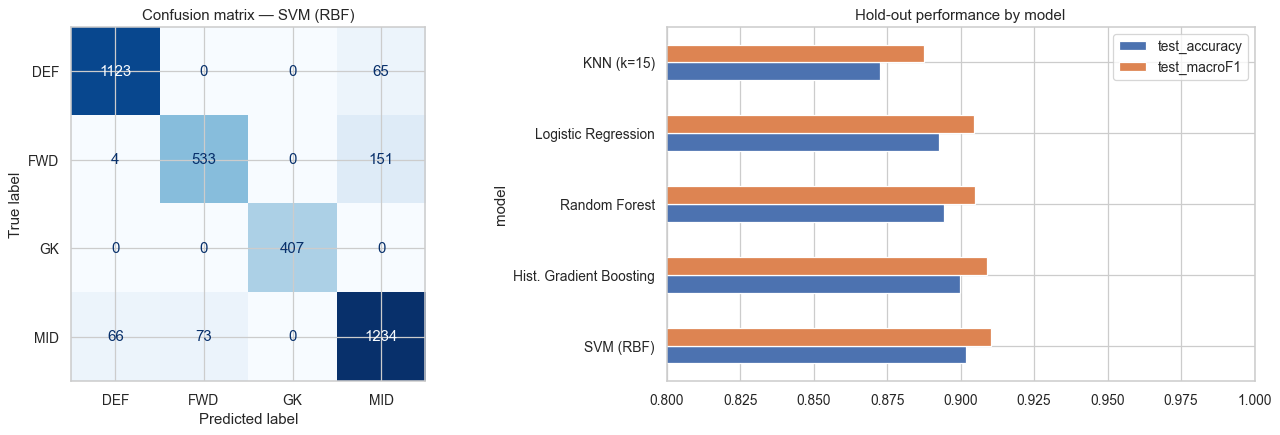

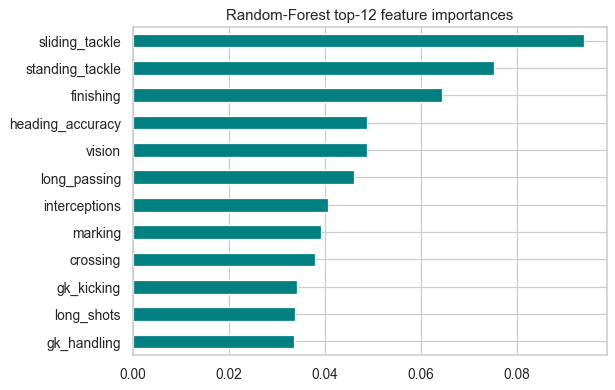

In [29]:
best_name = sup_res.index[0]; best = fitted[best_name]
print('Best model on hold-out macro-F1:', best_name, '\n')
pred = best.predict(X_te)
print(classification_report(y_te, pred, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ConfusionMatrixDisplay.from_predictions(y_te, pred, ax=axes[0], cmap='Blues', colorbar=False); axes[0].set_title(f'Confusion matrix — {best_name}')
sup_res[['test_accuracy', 'test_macroF1']].plot.barh(ax=axes[1]); axes[1].set_xlim(.8, 1); axes[1].set_title('Hold-out performance by model')
plt.tight_layout()

rf = fitted['Random Forest']
imp = pd.Series(rf.feature_importances_, index=CLUSTER_FEATURES).sort_values(ascending=False).head(12)
plt.figure(figsize=(7, 4.5)); imp[::-1].plot.barh(color='teal'); plt.title('Random-Forest top-12 feature importances'); plt.tight_layout()

### A3. Packaging for production
The winning classifier and the clustering pipeline are saved with `joblib`, and a small scoring function shows how a *new* player would be processed (same scaler → same PCA → same K-Means).

In [30]:
import joblib
# Production rule: among models within 0.005 macro-F1 of the best, pick the one with the fastest inference
close = sup_res[sup_res.test_macroF1 >= sup_res.test_macroF1.max() - 0.005]
prod_name = close.predict_ms_per_player.idxmin()
print('Candidates within 0.005 of the best:', list(close.index), '-> production model:', prod_name)
os.makedirs('models', exist_ok=True)
joblib.dump(fitted[prod_name], 'models/position_classifier.joblib')
joblib.dump({'scaler': scaler_out, 'pca': pca_out, 'kmeans': km_out, 'features': OUT_FEATURES, 'cluster_names': names},
            'models/outfield_archetype_clusters.joblib')

def score_player(row: pd.Series) -> dict:
    """Return predicted role and (for outfielders) the skill archetype for one player's attribute row."""
    clf = joblib.load('models/position_classifier.joblib')
    role = clf.predict(row[CLUSTER_FEATURES].to_frame().T.astype(float))[0]
    out = {'predicted_role': role}
    if role != 'GK':
        art = joblib.load('models/outfield_archetype_clusters.joblib')
        z = art['pca'].transform(art['scaler'].transform(row[art['features']].to_frame().T.astype(float)))
        out['archetype'] = art['cluster_names'][int(art['kmeans'].predict(z)[0])]
    else:
        out['archetype'] = 'Goalkeepers'
    return out

for i in [0, 3, 100, 5000]:
    r = df.loc[i]; print(f"{r.short_name:22s} actual={r.position_group:3s} ->", score_player(r))

Candidates within 0.005 of the best: ['SVM (RBF)', 'Hist. Gradient Boosting'] -> production model: Hist. Gradient Boosting
L. Messi               actual=FWD -> {'predicted_role': 'FWD', 'archetype': 'Elite creative attackers & playmakers'}
J. Oblak               actual=GK  -> {'predicted_role': 'GK', 'archetype': 'Goalkeepers'}
G. Bale                actual=FWD -> {'predicted_role': 'FWD', 'archetype': 'Elite creative attackers & playmakers'}
M. Araujo              actual=DEF -> {'predicted_role': 'DEF', 'archetype': 'Physical centre-backs'}


## Report A — Summary & recommendation

**A1 – Clustering.** K-Means gives the best compactness/separation (highest silhouette 0.17, lowest Davies-Bouldin 1.67, highest Calinski-Harabasz), is by far the cheapest (≈0.1 s) and yields the most balanced clusters (smallest cluster 21 % of players). Ward hierarchical clustering agrees slightly better with the real positions (ARI 0.28) but is slower, memory-hungry (O(n²), would not scale to the full 16k players without sampling) and cannot score new players. The Gaussian Mixture model performs worst (silhouette 0.06) — the skill space is not made of Gaussian blobs. → **K-Means (on standardised + PCA features) is the clustering model to productionise.**

**A2 – Supervised role classifier.** All models score ≈ 0.89–0.91 macro-F1; the top four are statistically indistinguishable (CV std ≈ 0.002; gap between SVM and Gradient Boosting is 0.0014). Goalkeepers are classified perfectly; the remaining errors are almost all *forward ↔ midfielder* (wide attackers whose skill sets look like an attacking midfielder's), i.e. genuine role ambiguity in the game data, not a modelling failure.

| Model | Test macro-F1 | Inference | Comment |
|---|---|---|---|
| SVM (RBF) | **0.910** | 0.26 ms/player | best score by a hair, slowest to score, no native probabilities |
| **Hist. Gradient Boosting** | 0.909 | **0.013 ms/player** | ≈ best score, 20× faster than SVM, handles non-linearity, easy to retrain |
| Random Forest | 0.905 | 0.04 ms | slowest to train (27 s) |
| Logistic Regression | 0.905 | 0.001 ms | simple, transparent baseline |
| KNN | 0.887 | 0.06 ms | weakest, keeps all training data |

**Recommendation for production:** `Histogram Gradient Boosting` for role prediction (within 0.0014 F1 of the best model but ~20× faster and cheap to retrain), with **Logistic Regression** as the interpretable fallback, and the **Scaler → PCA → K-Means** pipeline for archetype assignment. Both are saved in `models/`. Before deployment I would add monitoring for data drift (new FIFA editions rescale ratings) and retrain yearly.

---
# Findings for Task 2 and Task 3

## Task 2 — what the clusters say
* Goalkeepers form a perfectly separate group (2,036 players).
* The 16,242 outfield players split into **four archetypes**:

| Cluster | Size | Make-up | Profile |
|---|---|---|---|
| **Physical centre-backs** | 3,449 | 70 % CB, plus CDM/full-backs | highest strength (71) with solid tackling/heading; very weak finishing (28), dribbling (44) and vision (39) |
| **Defensive all-rounders (DM / full-back / top CB)** | 4,808 | CB, CDM, CM, LB/RB | highest aggression (68) and stamina (73), good tackling/interceptions; better rated (avg 67.7) — includes top centre-backs such as van Dijk |
| **Strikers & wide forwards** | 4,398 | 41 % ST + wingers/wide mids + CAM | fast (acceleration/sprint ≈ 71) with moderate finishing (58) and positioning (59) and the weakest defending (tackling 30); youngest group (avg age 23) |
| **Elite creative attackers & playmakers** | 3,587 | CM, CAM, ST, wide players | best ball control (74), dribbling (73), passing (72), vision (69), composure (71), finishing (66) and pace; avg overall 73, median value ≈ €3.9 M vs < €1 M elsewhere |

* **Caveat (honest reading):** outfield cluster quality is modest (silhouette ≈ 0.17). Skills are a *continuum*, and with k = 4 one cluster captures *how good* a player is across technical skills, not only *what role* he plays — which is why Messi, Ronaldo, De Bruyne and Modrić sit together. Clusters are useful archetypes for scouting, not hard categories.

## Task 3 answers

**Q1 — Top-10 countries (rank-ordered):** 1 England (1,667), 2 Germany (1,216), 3 Spain (1,035), 4 France (984), 5 Argentina (886), 6 Brazil (824), 7 Italy (732), 8 Colombia (591), 9 Japan (453), 10 Netherlands (416) — together **≈ 48 % of all players**. Quantity ≠ quality: England leads on count but only 26 of its players are rated 80+, while **Spain (92)** and Germany (43) have far more elite players and Brazil has the highest average rating of the ten (71.2). England's count is inflated because the game licenses several lower English divisions; Colombia and Japan are high-volume, low-elite-share suppliers.

**Q2 — Overall vs age:** Average overall rises quickly through the early 20s (≈ 61 at 20 → 67 at 24, +1–2 points a year), the yearly gain drops below ½ point at **age 26** and the average gap between *potential* and *overall* is gone by **age 27**; after ≈ 27–28 the curve is essentially flat (≈ 69–70). **Players stop improving at about 27 (26–28)**, then plateau into the early 30s and decline after ≈ 35. Cautions: (i) the "peak" of the mean at 35 is survivorship bias — only good players are still listed that old; (ii) data are cross-sectional, and EA's potential equals overall from ≈ 31, so the gap partly reflects game design.

**Q3 — Best-paid offensive position:** by *average* weekly wage the **right-winger** earns most (≈ €15.9 K) ahead of the left-winger (≈ €14.2 K) and striker (≈ €10.3 K); among players rated 75+ the median RW also leads (≈ €43 K vs LW €39 K, ST €32 K). However the **median wage is the same (€4 K) for all three**, a Kruskal-Wallis test finds **no statistically significant difference** (p = 0.86), and after controlling for overall rating, age and international reputation the position effect disappears (RW −6.5 %, LW −4.1 % vs ST). The right-winger "premium" comes from a few superstars (Messi, Salah …), not from a systematic pay structure — **talent and reputation drive pay, not the specific forward position**.

---
# REPORT B — Challenges faced and techniques used

| # | Challenge | Technique used | Why |
|---|---|---|---|
| 1 | **Large share of missing values** (up to 94 % in tags/loan/national-team columns; 11 % for pace…physic and every positional rating; 240 players with no contract data) | Inspected *why* values were missing (all GKs lack outfield composites; free agents lack contract info), dropped columns that were > 80 % empty / identifier-like, dropped the derived composites and used the complete raw attributes instead | The gaps are structural, not random — imputing a goalkeeper's "pace" or "finishing" would invent data and distort clusters |
| 2 | **Positional ratings stored as text** (`'89+2'`) | Parsed and summed into numeric values | Models and plots need numbers; the "+n" is an in-game bonus that belongs to the rating |
| 3 | **Multi-valued / categorical fields** (`player_positions`, `work_rate`, `preferred_foot`) | Took the primary position, grouped into GK/DEF/MID/FWD; split work-rate into attack/defence and encoded Low/Med/High as 0/0.5/1; encoded foot 0/1 as specified in the brief | Keeps ordinal meaning and avoids high-cardinality one-hot columns |
| 4 | **Extremely skewed money variables** (skew 6–8, ~13 % IQR "outliers") | Kept outliers (they are real stars), used log scales, medians and non-parametric tests (Kruskal-Wallis, Mann-Whitney) and a log-wage regression | Removing superstars would delete the very players of interest; means and t-tests would be misleading |
| 5 | **Zero wage / zero value rows** (240 / 250, mostly players without a club and national-team squads) | Excluded wage = 0 rows from the pay analysis and national teams from the club ranking | They are "no contract" records, not players earning €0 |
| 6 | **Duplicate-meaning columns** (`dribbling` composite vs `skill_dribbling`, GK composites vs `goalkeeping_*`) | Dropped the composites, renamed the raw skills to the brief's names | Prevents name clashes and double counting |
| 7 | **High multicollinearity** (tackles/interceptions/marking r > 0.9; dribbling–ball control 0.94) | Standardised all features and applied PCA (90 % variance → 11–15 components) before K-Means | K-Means uses Euclidean distance; correlated blocks would be over-weighted |
| 8 | **Goalkeepers dominate the cluster structure** (k = 2 silhouette 0.54 is only "GK vs rest") | Two-stage clustering: GKs form a fixed cluster, outfield players are clustered separately without GK features | Gives a meaningful split instead of one trivial cluster plus one giant blob |
| 9 | **Choosing k with no ground truth / weak cluster separation** (silhouette ≈ 0.17–0.25) | Used elbow, silhouette, Davies-Bouldin, Calinski-Harabasz, cluster sizes and interpretability (crosstab against position, profile heatmap) together; reported the weak separation openly | No single metric is reliable on a continuous skill space |
| 10 | **Target leakage risk** (overall, potential, position ratings) | Excluded `overall`, `potential`, positional ratings and position from model inputs, used them only to *interpret* clusters | As the brief requires — otherwise clusters would merely rank players by quality |
| 11 | **Computational cost of silhouette / hierarchical models on 18 k rows** | Used sampled silhouette (6–8 k) and a fixed 6,000-row benchmark sample for model comparison | O(n²) memory/time; sampling keeps results stable and fast |
| 12 | **Age-vs-rating question is confounded** (cross-sectional data, survivorship bias, potential = overall for 31+) | Looked at several indicators (yearly gain, potential gap, mean and 90th-percentile curve), required ≥ 50 players per age, and stated the caveats | A single curve of means would wrongly suggest players peak at 35 |
| 13 | **Brief mentions FIFA 15–20 but only FIFA 20 supplied** | Did single-version equivalents (e.g. Messi vs Ronaldo skill comparison) and noted the limitation | Time-trend questions cannot be answered from one snapshot |
| 14 | **Near-tied supervised models** | Compared by CV and hold-out macro-F1, training time and inference latency, and set an explicit rule (within 0.005 F1 → fastest) | Differences of ≈ 0.001 F1 are noise; operational cost should break the tie |

---
# Overall conclusion
* The FIFA 20 data is clean once structural missingness is understood; the key preparation work was parsing, encoding, dropping composites and handling skew.
* Player skills fall into **five archetypes** (GK + four outfield groups) that map sensibly onto football roles, with the caveat that skills form a continuum.
* **Spain, Brazil and Germany** produce the most *elite* players; England, Germany and Spain produce the most players overall.
* Players **stop improving around age 27**.
* **Striker, RW and LW are paid statistically the same** once quality is considered.
* For deployment: **K-Means (scaler → PCA)** for archetypes and **Gradient Boosting** for role prediction.